In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold

from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE, ADASYN


In [42]:
plt.rcParams.update({
    'figure.facecolor': 'white',
    'figure.dpi':       120,
    'savefig.dpi':      150,
    'axes.titleweight': 'bold',
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'axes.facecolor':   '#fafafa',
    'axes.edgecolor':   '#cccccc',
    'axes.grid':        True,
    'grid.color':       '#e0e0e0',
    'grid.linestyle':   '--',
    'grid.linewidth':   0.5,
    'font.size':        13,
    'lines.linewidth':  1.6,
})

COLORS = {1: '#2196F3', 2: '#FF5722', 4: '#4CAF50',
          'err': '#E91E63', 'neutral': '#607D8B'}

SEED = 67
np.random.seed(SEED)


In [43]:
df_raw = pd.read_excel('data_set.xlsx')
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   I1      234 non-null    float64
 1   I2      234 non-null    float64
 2   I3      234 non-null    float64
 3   gx      234 non-null    float64
 4   gy      234 non-null    float64
 5   gz      234 non-null    float64
 6   ax      234 non-null    float64
 7   ay      234 non-null    float64
 8   az      234 non-null    float64
 9   V1real  234 non-null    float64
 10  V2real  234 non-null    float64
 11  V3real  234 non-null    float64
 12  N1      234 non-null    int64  
 13  N2      234 non-null    int64  
 14  N3      234 non-null    int64  
 15  Type    234 non-null    int64  
dtypes: float64(12), int64(4)
memory usage: 29.4 KB


In [44]:
df_raw.describe().T.drop('count', axis=1)


,mean,std,min,25%,50%,75%,max
I1,0.492650,0.313126,0.037607,0.274038,0.381920,0.721795,1.365008
I2,0.499278,0.408771,0.000000,0.245299,0.380342,0.725428,1.561085
I3,0.519289,0.304878,0.029060,0.291173,0.403419,0.792789,1.223229
gx,0.551656,1.854694,-16.461250,0.015564,0.535205,0.860971,9.905385
gy,-0.941170,1.881397,-6.236250,-1.646667,-0.181157,0.276912,3.088000
gz,22.044871,28.461754,-4.251176,0.551108,6.452208,37.370500,88.294667
ax,0.002398,0.017036,-0.062402,-0.004853,0.002026,0.011218,0.100601
ay,-0.003050,0.025254,-0.132782,-0.014530,-0.001333,0.008341,0.100656
az,-0.001305,0.021437,-0.116547,-0.009810,-0.000774,0.006682,0.087982
V1real,168.392466,315.757522,-300.600000,-109.350000,155.769231,345.150000,772.200000


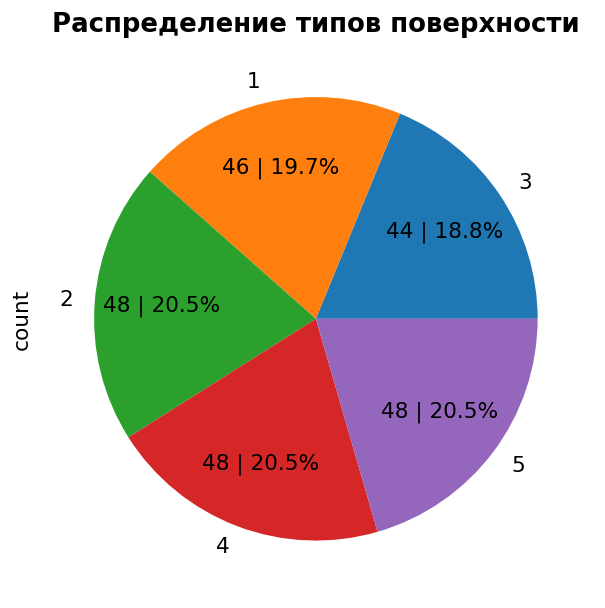

In [45]:
def plot_pie_distribution(df, title='Распределение типов поверхности'):
    plt.figure(figsize=(6, 6))
    plt.title(title)
    count = df['Type'].count()
    df['Type'].value_counts().sort_values().plot.pie(
        autopct=lambda pct: f'{int(count*pct/100)} | {pct:.1f}%',
        pctdistance=0.7
    )
    plt.show()

plot_pie_distribution(df_raw)


Распределение типов поверхности практически равномерное (~46–48 примеров на класс). Делим на обучающую A+B и контрольную C, сохраняя стратификацию.

A+B: 187 примеров
C:   47 примеров


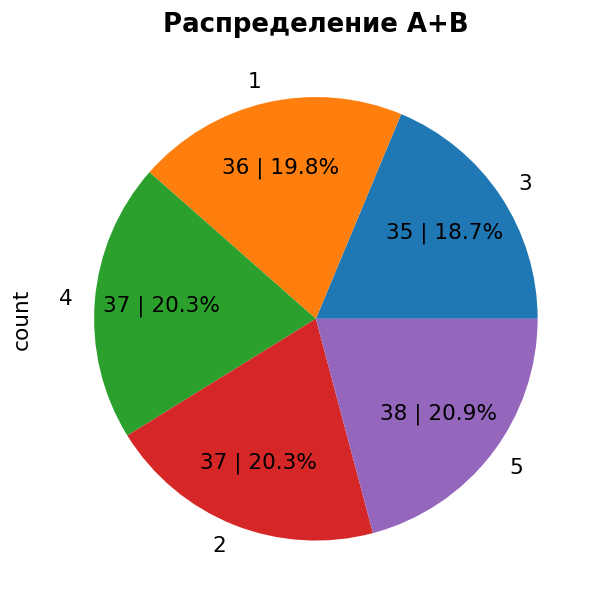

In [46]:
df_AB_raw, df_C_raw = train_test_split(
    df_raw, test_size=0.2, random_state=SEED, stratify=df_raw['Type']
)
print(f'A+B: {len(df_AB_raw)} примеров')
print(f'C:   {len(df_C_raw)} примеров')
plot_pie_distribution(df_AB_raw, title='Распределение A+B')


## Вычисление признаков V2

**{V2}** = {Vx, Vy, V_full, Ω, Ix, Iy, I_φ, I_Σ} — абсолютные кинематические и токовые параметры, полученные кинематическими преобразованиями. В отличие от сырых показаний энкодеров/двигателей, эти признаки описывают движение в мировых координатах и не зависят от направления вектора скорости.


In [47]:
def compute_V2(df):
    R = 0.04; L = 0.125; theta = np.deg2rad(30); alpha = 0.0
    w1, w2, w3 = df['V1real'], df['V2real'], df['V3real']
    c1, c2, c3 = df['I1'],     df['I2'],     df['I3']
    out = df.copy()
    out['Vx']      = R * (-(2/3)*np.cos(alpha-theta)*w1 + (2/3)*np.sin(alpha)*w2 + (2/3)*np.cos(alpha+theta)*w3)
    out['Vy']      = R * (-(2/3)*np.sin(alpha-theta)*w1 - (2/3)*np.cos(alpha)*w2 + (2/3)*np.sin(alpha+theta)*w3)
    out['V_full']  = np.sqrt(out['Vx']**2 + out['Vy']**2)
    out['Omega']   = (w1 + w2 + w3) / (3 * L)
    c1s = c1*np.sign(w1); c2s = c2*np.sign(w2); c3s = c3*np.sign(w3)
    out['Ix']      = -(2/3)*np.cos(alpha-theta)*c1s + (2/3)*np.sin(alpha)*c2s + (2/3)*np.cos(alpha+theta)*c3s
    out['Iy']      = -(2/3)*np.sin(alpha-theta)*c1s - (2/3)*np.cos(alpha)*c2s + (2/3)*np.sin(alpha+theta)*c3s
    out['I_phi']   = (c1s + c2s + c3s) / 3
    out['I_sigma'] = np.abs(c1) + np.abs(c2) + np.abs(c3)
    return out

FEAT_V2 = ['Vx', 'Vy', 'V_full', 'Omega', 'Ix', 'Iy', 'I_phi', 'I_sigma']

df_AB = compute_V2(df_AB_raw)
df_C  = compute_V2(df_C_raw)
print('V2-признаки:', FEAT_V2)


V2-признаки: ['Vx', 'Vy', 'V_full', 'Omega', 'Ix', 'Iy', 'I_phi', 'I_sigma']


## Разведочный анализ признаков V2 (по обучающей выборке A+B)

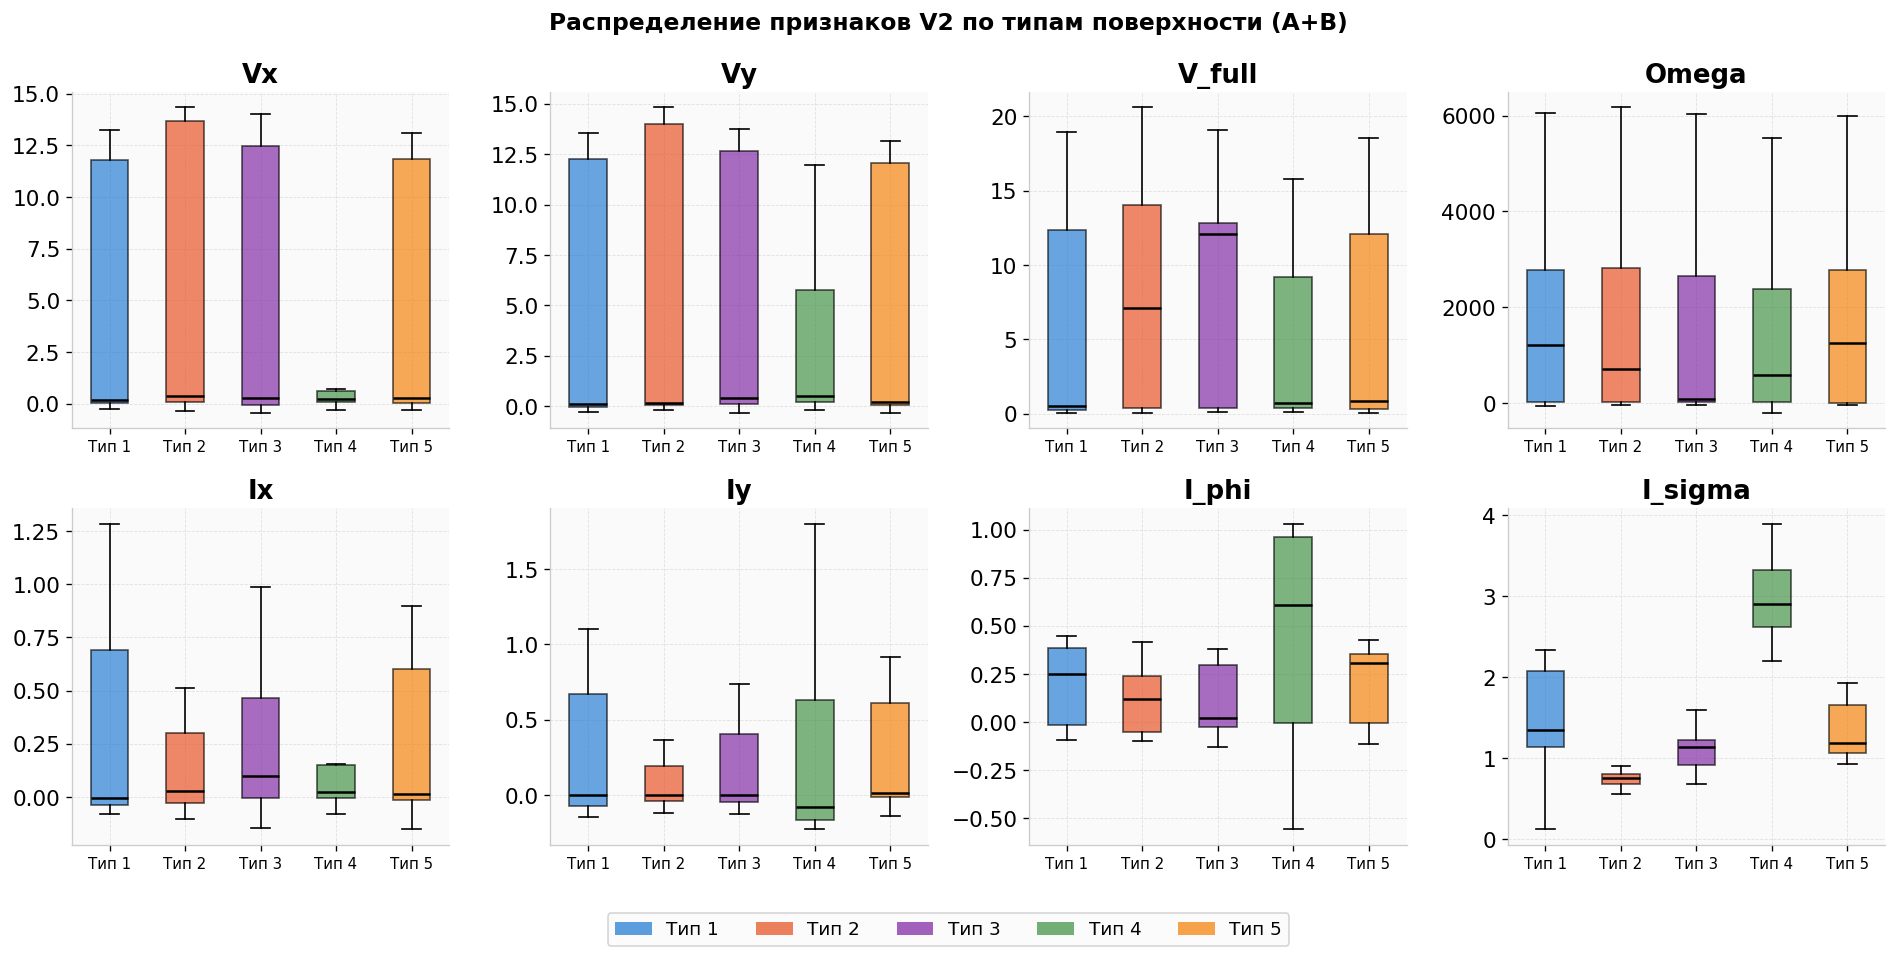

In [48]:
type_colors = {1: '#1976D2', 2: '#E64A19', 3: '#7B1FA2', 4: '#388E3C', 5: '#F57C00'}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for idx, feat in enumerate(FEAT_V2):
    ax = axes.flat[idx]
    bp = ax.boxplot(
        [df_AB.loc[df_AB['Type'] == t, feat].values for t in [1,2,3,4,5]],
        patch_artist=True, showfliers=False,
        medianprops=dict(color='black', linewidth=1.5)
    )
    for patch, t in zip(bp['boxes'], [1,2,3,4,5]):
        patch.set_facecolor(type_colors[t]); patch.set_alpha(0.65)
    ax.set_xticks(range(1,6))
    ax.set_xticklabels([f'Тип {t}' for t in [1,2,3,4,5]], fontsize=9)
    ax.set_title(feat, fontweight='bold')

handles = [Patch(facecolor=type_colors[t], alpha=0.7, label=f'Тип {t}') for t in [1,2,3,4,5]]
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=11)
fig.suptitle('Распределение признаков V2 по типам поверхности (A+B)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


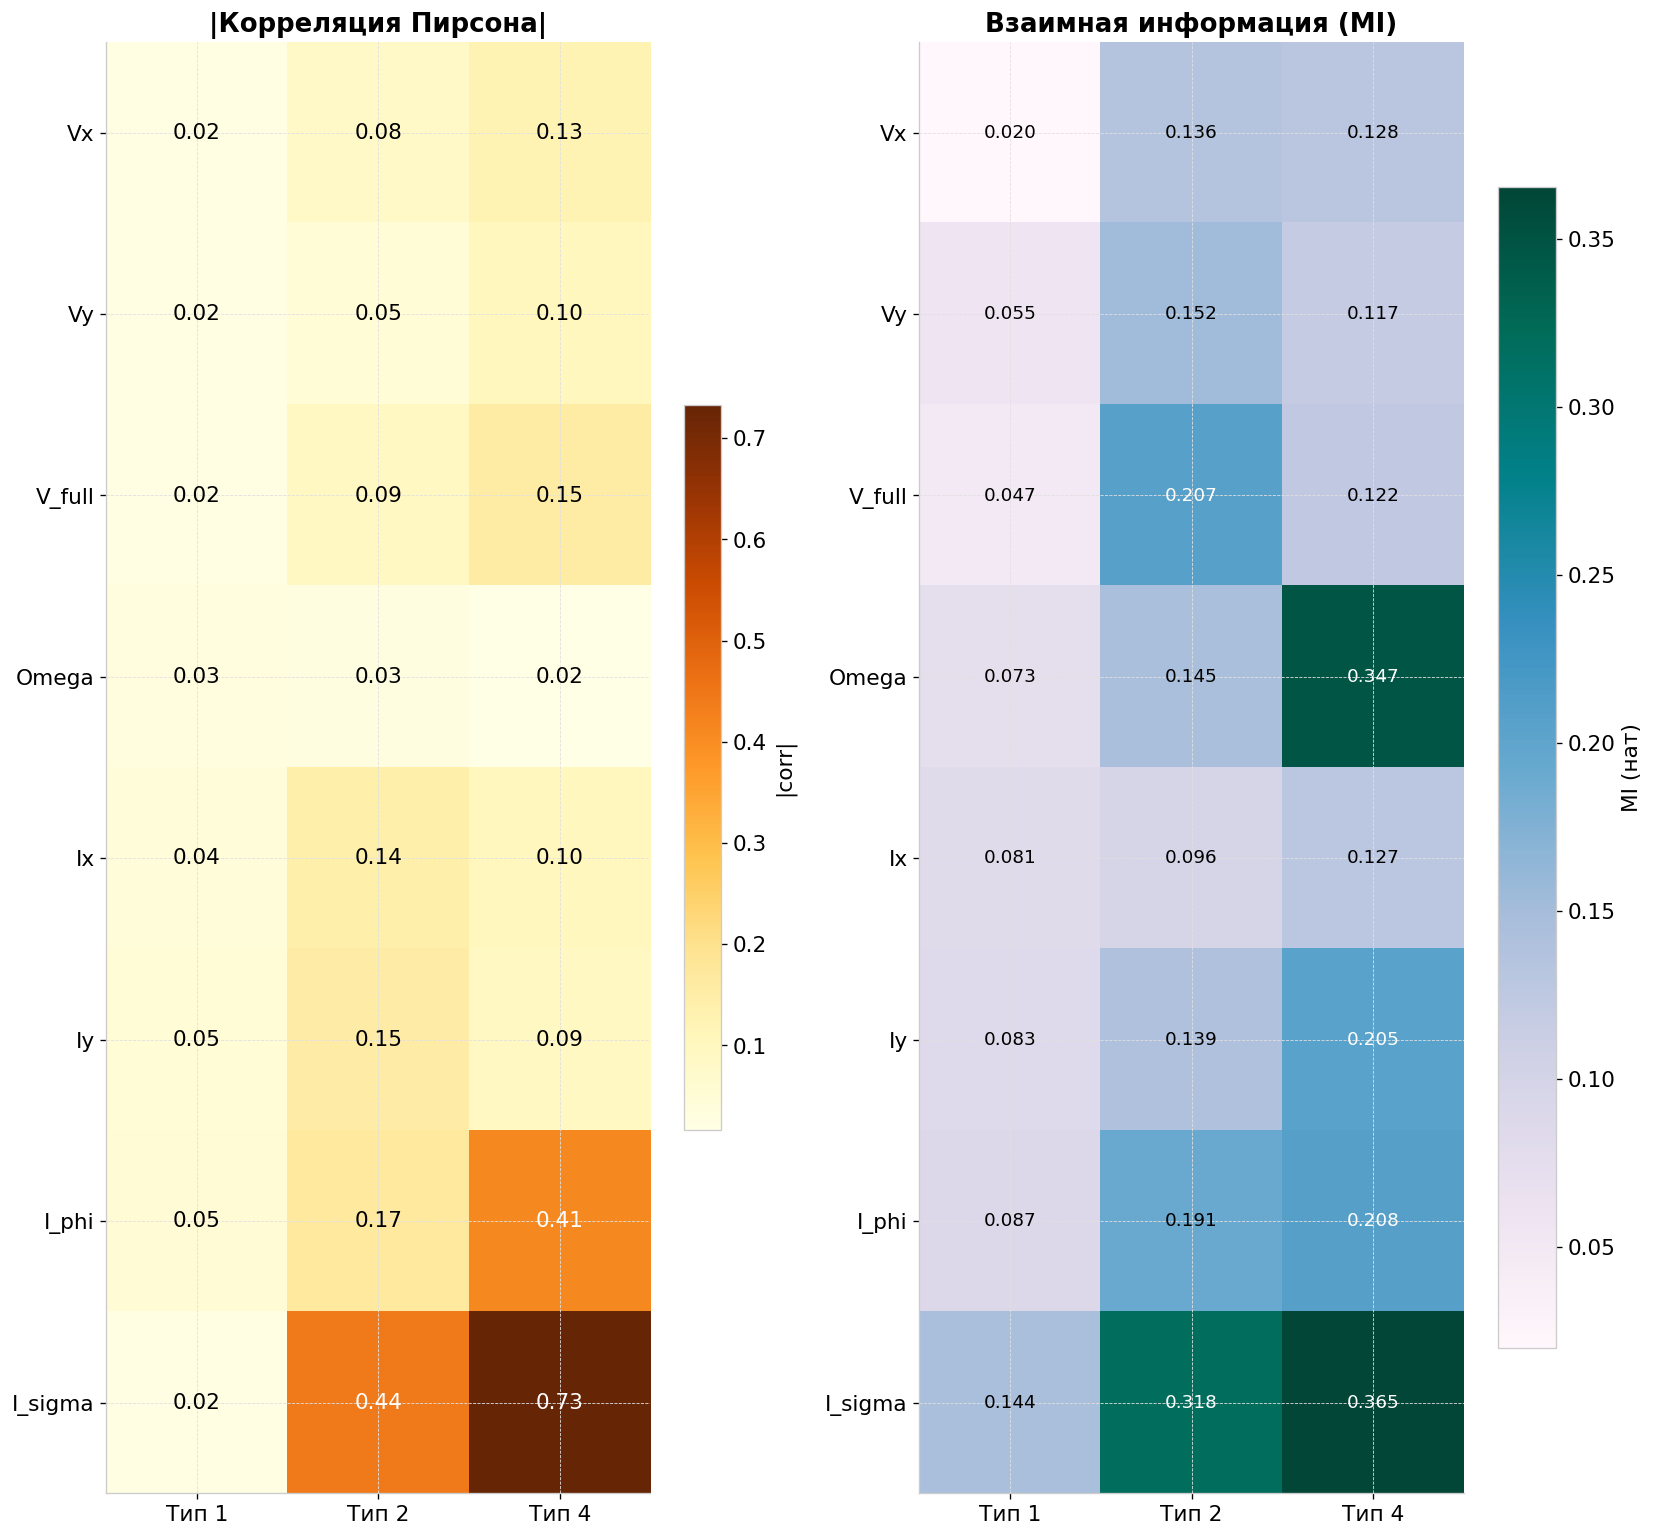

In [49]:
# Корреляция
corr_data = {}
for t in [1, 2, 4]:
    y_bin = (df_AB['Type'] == t).astype(int)
    corr_data[t] = df_AB[FEAT_V2].corrwith(y_bin).abs()
corr_df = pd.DataFrame(corr_data).rename(columns=lambda c: f'Тип {c}')

# Взаимная информация для трёх бинарных классификаторов
mi_data = {}
for t in [1, 2, 4]:
    y_bin = (df_AB['Type'] == t).astype(int)
    mi_vals = mutual_info_classif(df_AB[FEAT_V2], y_bin, random_state=SEED, n_neighbors=5)
    mi_data[f'Тип {t}'] = pd.Series(mi_vals, index=FEAT_V2)
mi_df = pd.DataFrame(mi_data)

# Визуализация: два heatmap рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 13))

im1 = ax1.imshow(corr_df.values, aspect='auto', cmap='YlOrBr')
ax1.set_xticks(range(3)); ax1.set_xticklabels(corr_df.columns)
ax1.set_yticks(range(len(FEAT_V2))); ax1.set_yticklabels(FEAT_V2)
for i in range(len(FEAT_V2)):
    for j in range(3):
        v = corr_df.iloc[i, j]
        ax1.text(j, i, f'{v:.2f}', ha='center', va='center',
                 color='white' if v > 0.4 else 'black')
ax1.set_title('|Корреляция Пирсона|')
fig.colorbar(im1, ax=ax1, shrink=0.5, label='|corr|')

im = ax2.imshow(mi_df.values, aspect='auto', cmap='PuBuGn')
ax2.set_xticks(range(3)); ax2.set_xticklabels(mi_df.columns)
ax2.set_yticks(range(len(FEAT_V2))); ax2.set_yticklabels(FEAT_V2)
for i in range(len(FEAT_V2)):
    for j in range(3):
        v = mi_df.iloc[i, j]
        ax2.text(j, i, f'{v:.3f}', ha='center', va='center',
                color='white' if v > mi_df.values.max()*0.55 else 'black', fontsize=11)
ax2.set_title('Взаимная информация (MI)', fontweight='bold')
fig.colorbar(im, ax=ax2, shrink=0.8, label='MI (нат)')

plt.tight_layout(); plt.show()

**Наблюдения:**
- `I_sigma` и `I_phi` — наибольшая MI для всех трёх классов; токовые интегральные признаки несут максимум информации о типе поверхности.
- Скоростные признаки (`Vx`, `Vy`, `V_full`, `Omega`) вносят меньший, но ненулевой вклад — в частности для типов 1 и 2.
- `Ix`, `Iy` — проекции тока на мировые оси — дополнительно информативны для типа 4.

Все 8 признаков V2 используются во всех экспериментах.


## Вспомогательные функции и словари параметров

In [50]:
SCALERS = {
    'Standard': StandardScaler,
    'MaxAbs':   MaxAbsScaler,
    'MinMax':   MinMaxScaler,
}

BALANCERS = {
    'None':   lambda: None,
    'SMOTE':  lambda: SMOTE(random_state=SEED),
    'ADASYN': lambda: ADASYN(random_state=SEED),
}


In [51]:
# ─────────────────────────────────────────────────────────────────────────────
# Словари параметров по умолчанию для каждого типа поверхности.
# После каждого эксперимента обновляем нужный ключ, например:
#   classifier_params[1]['alpha'] = 0.1
# ─────────────────────────────────────────────────────────────────────────────

classifier_param_1 = dict(
    scaler    = 'Standard',
    balancer  = 'None',
    solver    = 'adam',
    layers    = (20,),
    activation= 'relu',
    alpha     = 0.001,
    max_iter  = 2000,
)

classifier_param_2 = dict(
    scaler    = 'Standard',
    balancer  = 'None',
    solver    = 'adam',
    layers    = (20,),
    activation= 'relu',
    alpha     = 0.001,
    max_iter  = 2000,
)

classifier_param_4 = dict(
    scaler    = 'Standard',
    balancer  = 'None',
    solver    = 'adam',
    layers    = (20,),
    activation= 'relu',
    alpha     = 0.001,
    max_iter  = 2000,
)

classifier_params = {
    1: classifier_param_1,
    2: classifier_param_2,
    4: classifier_param_4,
}


In [52]:
def params_info(p):
    """Строка с полной конфигурацией для заголовка графика."""    
    return (f"solver={p['solver']}  layers={p['layers']}  act={p['activation']}  "
            f"scaler={p['scaler']}  bal={p['balancer']}  "
            f"alpha={p['alpha']}  max_iter={p['max_iter']}")


def run_pipeline(surface_type, classifier_params, cv=3):
    """Обучает бинарный MLPClassifier на признаках V2 и возвращает метрики.

    Порядок шагов при обучении финальной модели:
        1. Балансировка (SMOTE / ADASYN / None) на исходных данных
        2. Обучение pipeline [Scaler -> MLP] на сбалансированной выборке

    Кросс-валидация выполняется отдельным pipeline [Scaler -> Balancer -> MLP]
    на исходных данных, чтобы балансировщик применялся
    корректно внутри каждого fold.

    Parameters
    ----------
    surface_type      : int  — тип поверхности (1, 2 или 4)
    classifier_params : dict — конфигурация классификатора
                        (scaler, balancer, solver, layers, activation, alpha, max_iter)
    cv                : int  — число фолдов кросс-валидации
    """
    scaler     = classifier_params['scaler']
    balancer   = classifier_params['balancer']
    solver     = classifier_params['solver']
    layers     = classifier_params['layers']
    activation = classifier_params['activation']
    alpha      = classifier_params['alpha']
    max_iter   = classifier_params['max_iter']

    X_orig = df_AB[FEAT_V2].copy()
    y_orig = (df_AB['Type'] == surface_type).astype(int)

    make_mlp = lambda: MLPClassifier(
        hidden_layer_sizes=layers, activation=activation,
        solver=solver, alpha=alpha, max_iter=max_iter, random_state=SEED,
    )

    # ── 1. Балансировка на исходных данных ──────────────────────────────────────────
    balancer_obj = BALANCERS[balancer]()
    if balancer_obj is not None:
        X_bal, y_bal = balancer_obj.fit_resample(X_orig, y_orig)
    else:
        X_bal, y_bal = X_orig.copy(), y_orig.copy()

    # ── 2. Финальная модель [Scaler -> MLP] ────────────────────────────────────────
    predictor = make_pipeline(SCALERS[scaler](), make_mlp())
    predictor.fit(X_bal, y_bal)

    # Оцениваем на исходных (несинтетических) данных
    pred_train = predictor.predict(X_orig)
    f1_train   = f1_score(y_orig, pred_train, zero_division=0)

    # ── CV: [Scaler -> (Balancer) -> MLP] на исходных данных ──
    cv_pipe = make_pipeline(SCALERS[scaler](), balancer_obj, make_mlp())
    cv_scores = cross_val_score(cv_pipe, X_orig, y_orig, cv=cv, scoring='f1')

    return {
        'model':predictor, 'f1':f1_train, 'cv':cv_scores,
        'y_train':y_orig, 'pred_train':pred_train,'y_balanced':y_bal,'n_balanced': len(y_bal),
    }


In [53]:
def plot_experiment_results(results, title):
    """Grouped bar chart: F1 на A+B (синий) и CV F1 со std (зелёный)."""    
    labels   = [r['label']       for r in results]
    f1_vals  = [r['f1']          for r in results]
    cv_means = [np.mean(r['cv']) for r in results]
    cv_stds  = [np.std(r['cv'])  for r in results]

    x = np.arange(len(labels)); w = 0.38
    fig, ax = plt.subplots(figsize=(max(10, len(labels)*1.4), 5))
    b1 = ax.bar(x - w/2, f1_vals,  w, label='F1 (A+B)',        color='#2196F3', alpha=0.85, zorder=3)
    b2 = ax.bar(x + w/2, cv_means, w, label='CV F1 (среднее)',  color='#4CAF50', alpha=0.85,
                yerr=cv_stds, capsize=4, zorder=3)
    for bar in b1:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f'{h:.3f}',
                ha='center', va='bottom', fontsize=9, color='#1565C0', fontweight='bold')
    for bar in b2:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.022, f'{h:.3f}',
                ha='center', va='bottom', fontsize=9, color='#2E7D32', fontweight='bold')
    ax.set_ylabel('Значение метрики')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right')
    ax.legend(loc='lower right', framealpha=0.9)
    ax.set_ylim(0, 1.22)
    ax.axhline(0.5, color='#bdbdbd', ls=':', lw=1, alpha=0.7)
    plt.tight_layout(); plt.show()


In [54]:
def plot_binary_classifier(y_true, y_pred, title=''):
    """График бинарного классификатора: истинные значения — сплошная линия, предсказания — красные крестики."""
    fig, ax = plt.subplots(figsize=(14, 3.5))
    ax.plot(range(len(y_true)), y_true.values if hasattr(y_true, 'values') else y_true,
            color='#1565C0', lw=1.4, label='Истинное значение', zorder=3)
    ax.scatter(range(len(y_pred)), y_pred, marker='x', color='#E53935',
               s=28, linewidths=1.2, label='Предсказание', zorder=4, alpha=0.85)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['0 (другие)', '1 (целевой)'])
    ax.set_xlabel('Номер примера')
    ax.set_ylabel('Класс')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax.set_ylim(-0.15, 1.25)
    plt.tight_layout()
    plt.show()


---
## Классификатор — Тип 1

Последовательный подбор гиперпараметров. Все зафиксированные значения хранятся в `classifier_params[1]`.

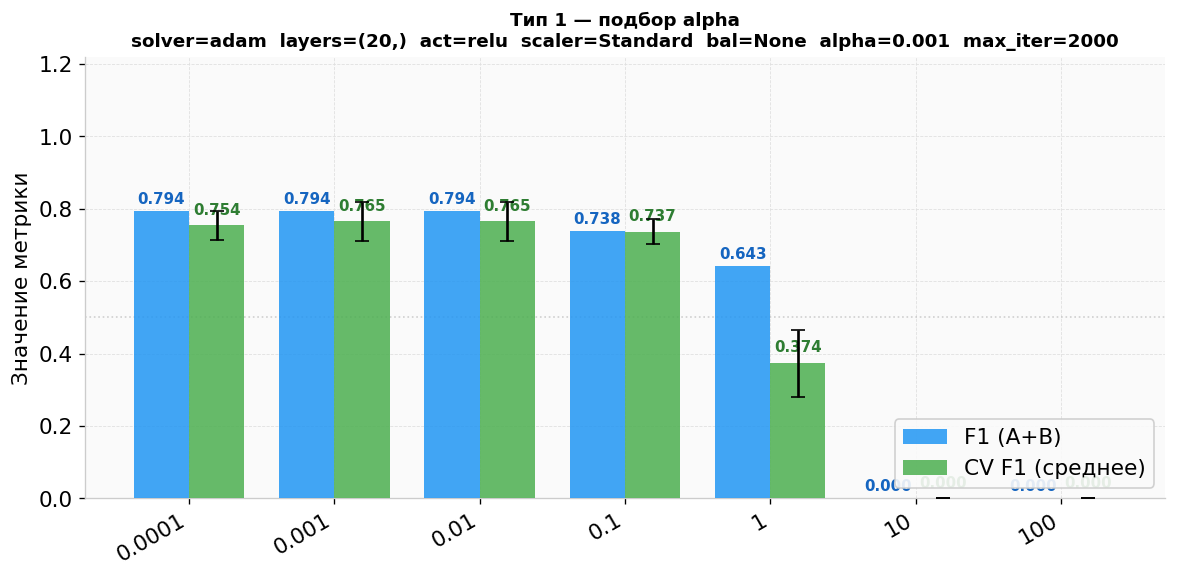

In [55]:
t = 1; p = classifier_params[t]

results = []
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'alpha': alpha})
    results.append({'label': str(alpha), 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — подбор alpha\n{params_info(p)}')


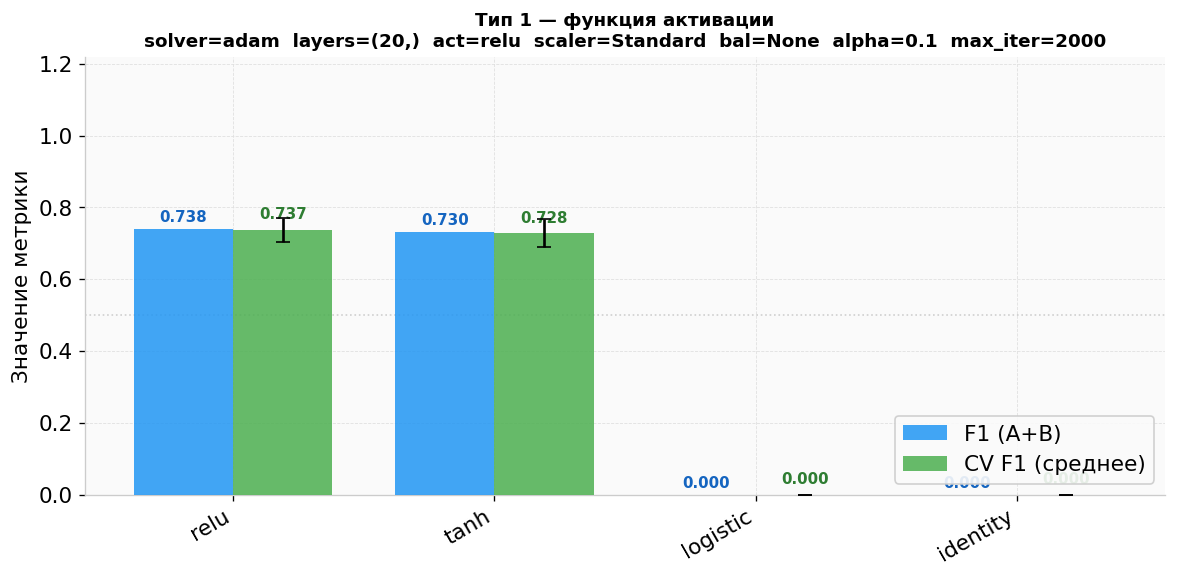

In [56]:
classifier_params[1]['alpha'] = 0.1
t = 1; p = classifier_params[t]

results = []
for act in ['relu', 'tanh', 'logistic', 'identity']:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'activation': act})
    results.append({'label': act, 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — функция активации\n{params_info(p)}')


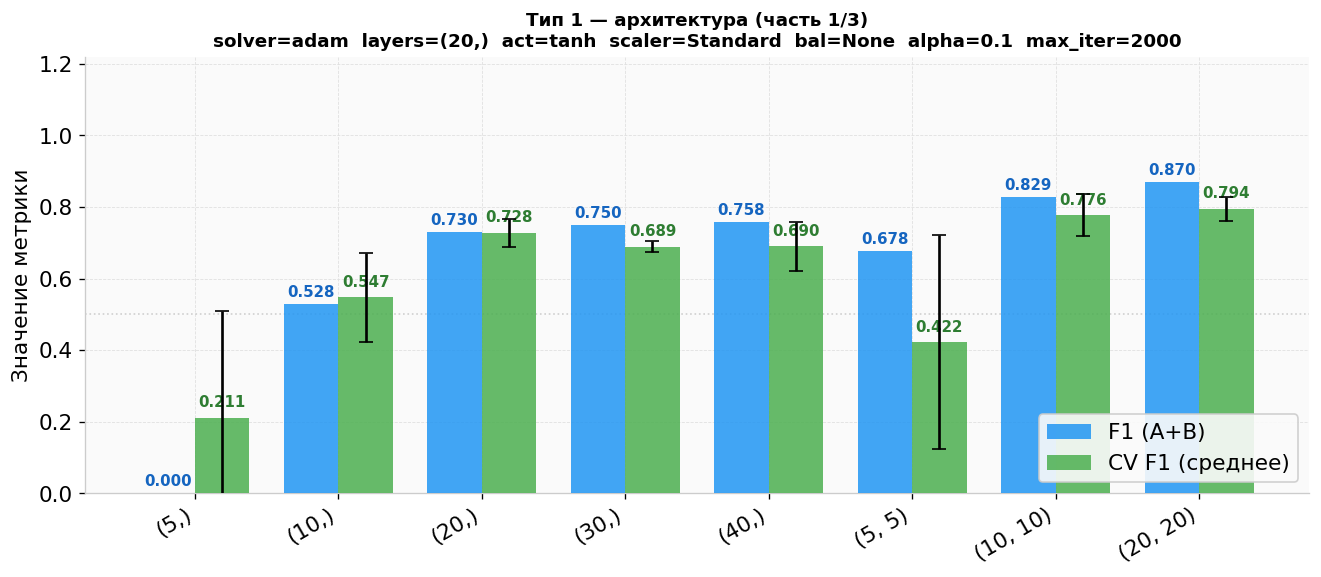

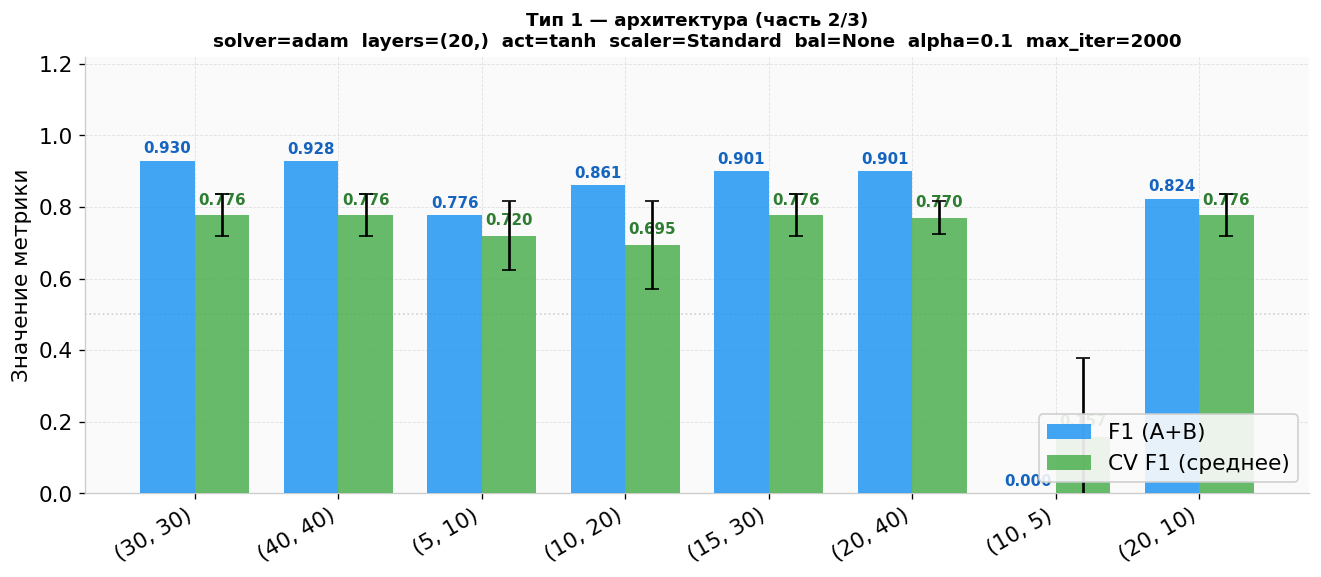

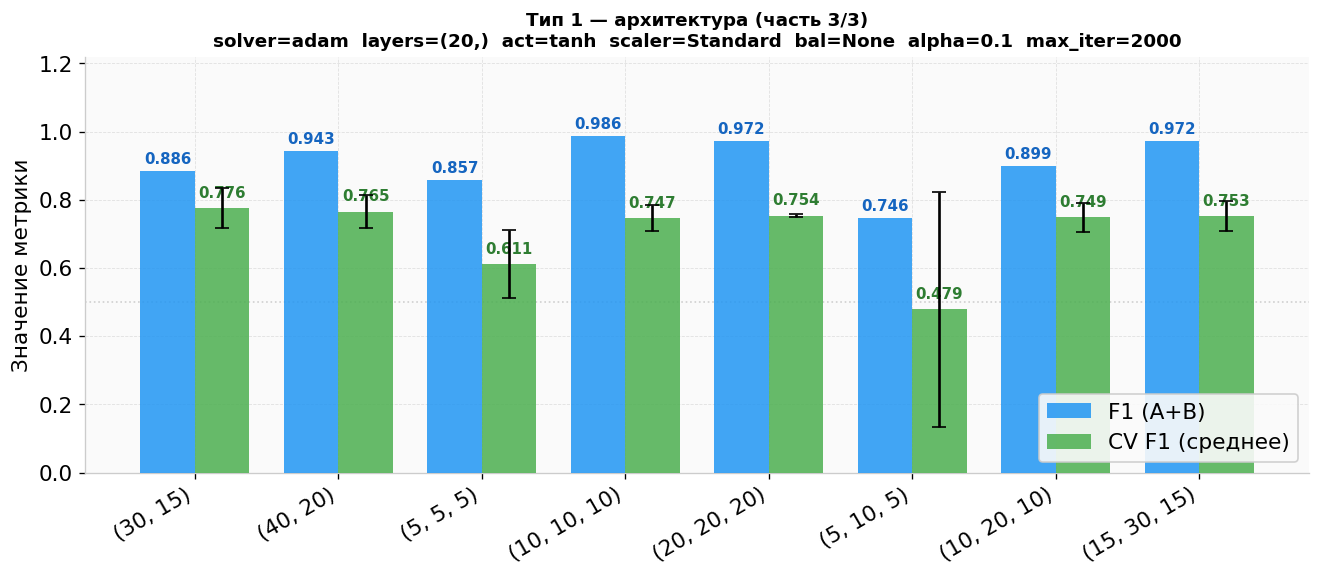

In [57]:
classifier_params[1]['activation'] = 'tanh'
t = 1; p = classifier_params[t]

layers_grid = [
    (5,),(10,),(20,),(30,),(40,),
    (5,5),(10,10),(20,20),(30,30),(40,40),
    (5,10),(10,20),(15,30),(20,40),
    (10,5),(20,10),(30,15),(40,20),
    (5,5,5),(10,10,10),(20,20,20),
    (5,10,5),(10,20,10),(15,30,15),
]
results = []
for layers in layers_grid:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'layers': layers})
    results.append({'label': str(layers), 'f1': r['f1'], 'cv': r['cv']})

for i, part in enumerate(np.array_split(results, 3)):
    plot_experiment_results(list(part),
        title=f'Тип {t} — архитектура (часть {i+1}/3)\n{params_info(p)}')


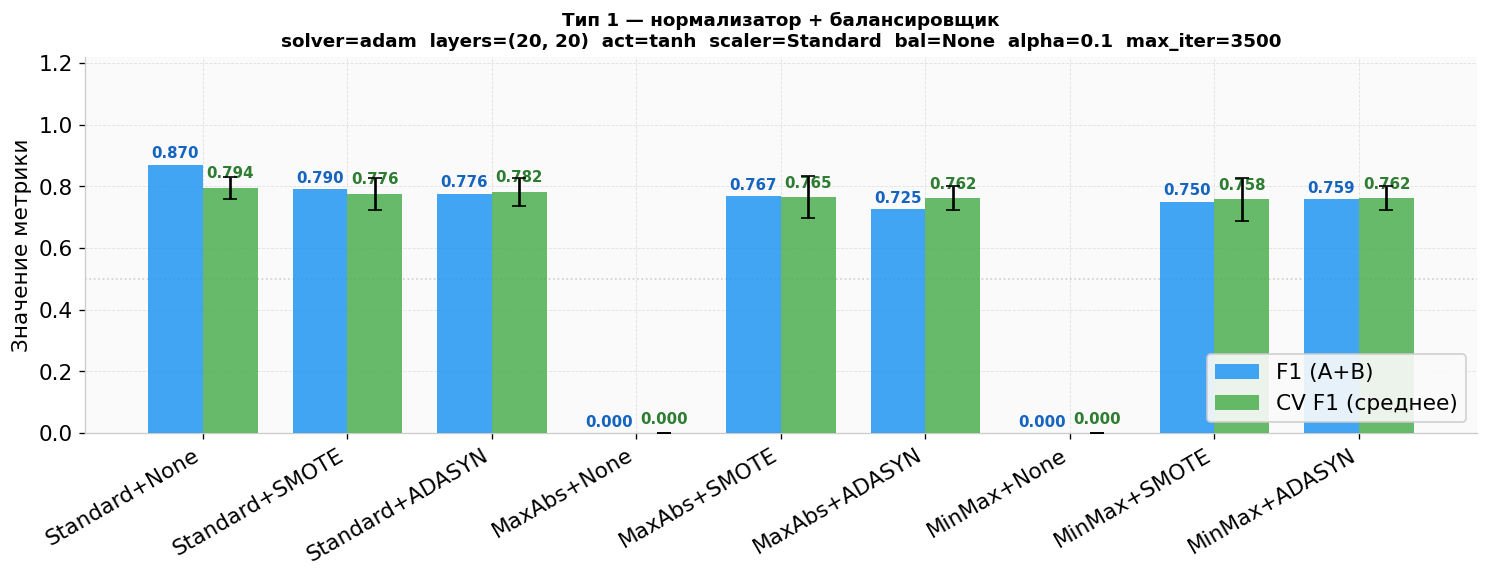

In [58]:
classifier_params[1]['layers'] = (20, 20)
t = 1; p = classifier_params[t]
p['max_iter'] = 3500

results = []
for scaler in SCALERS:
    for balancer in BALANCERS:
        r = run_pipeline(surface_type=t, classifier_params={**p, 'scaler': scaler, 'balancer': balancer})
        results.append({'label': f'{scaler}+{balancer}', 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — нормализатор + балансировщик\n{params_info(p)}')


In [59]:
classifier_params[1]['scaler']   = 'Standard'
classifier_params[1]['balancer'] = 'None'

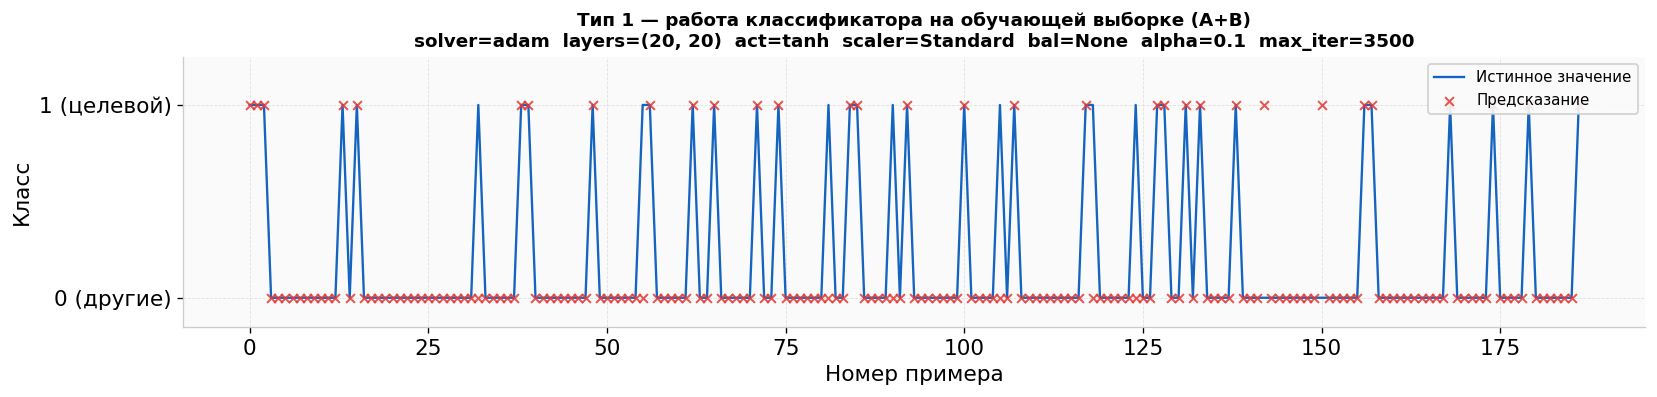

F1 на обучающей выборке: 0.8696,  CV F1: 0.7944 ± 0.0342


In [60]:
# Визуализация работы бинарного классификатора Тип 1 на обучающей выборке
t = 1; p = classifier_params[t]
r = run_pipeline(surface_type=t, classifier_params=p)
plot_binary_classifier(r['y_train'], r['pred_train'],
    title=f'Тип {t} — работа классификатора на обучающей выборке (A+B)\n{params_info(p)}')
print(f'F1 на обучающей выборке: {r["f1"]:.4f},  CV F1: {np.mean(r["cv"]):.4f} ± {np.std(r["cv"]):.4f}')


---
## Классификатор — Тип 2

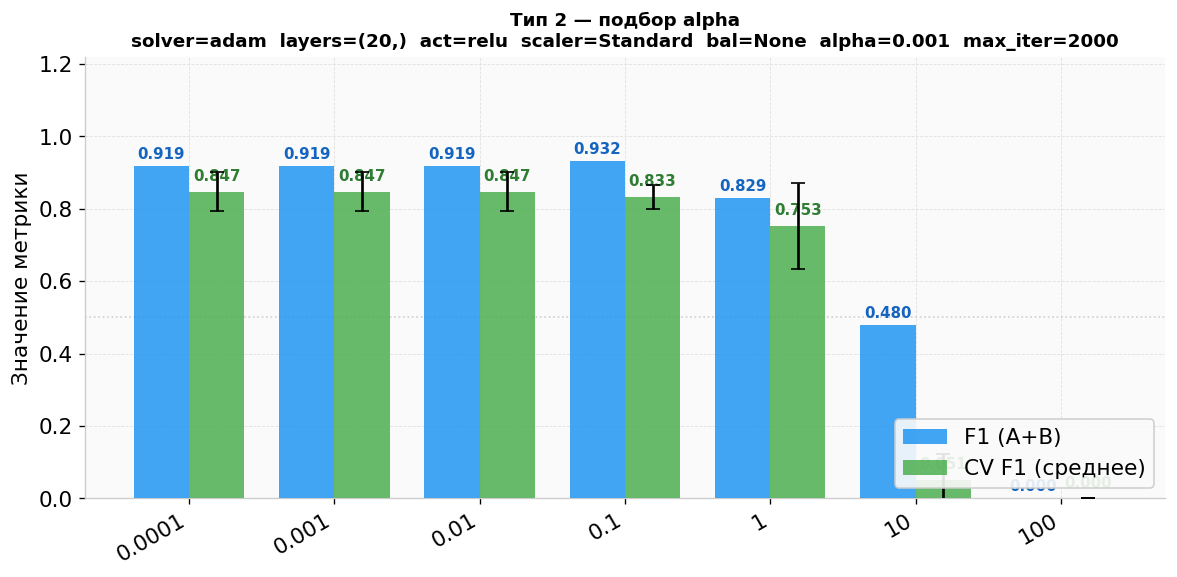

In [61]:
t = 2; p = classifier_params[t]

results = []
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'alpha': alpha})
    results.append({'label': str(alpha), 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — подбор alpha\n{params_info(p)}')


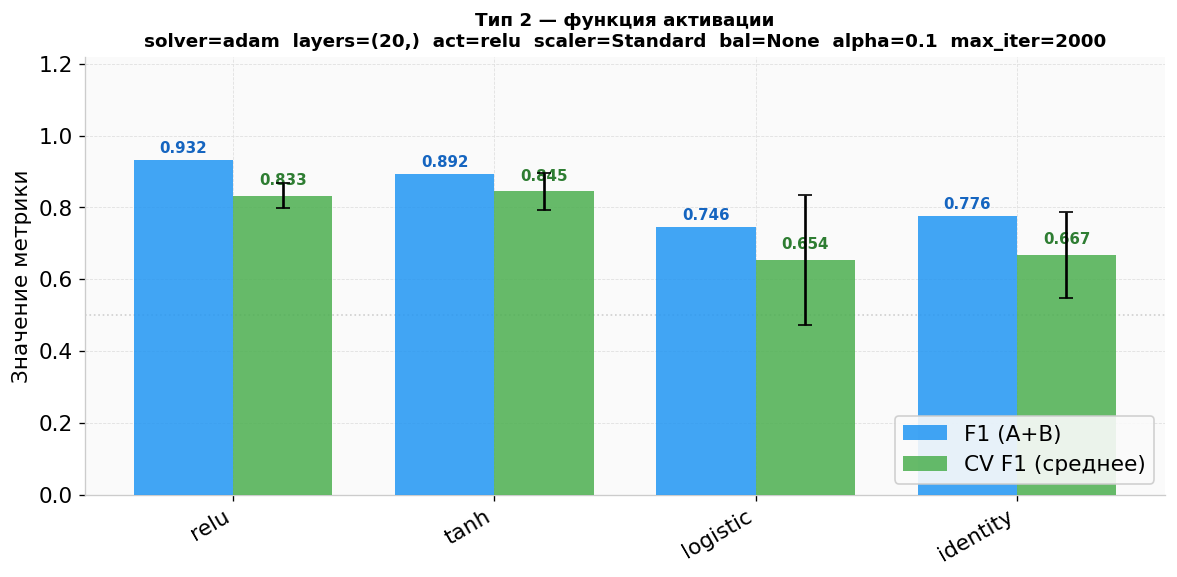

In [62]:
classifier_params[2]['alpha'] = 0.1
t = 2; p = classifier_params[t]

results = []
for act in ['relu', 'tanh', 'logistic', 'identity']:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'activation': act})
    results.append({'label': act, 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — функция активации\n{params_info(p)}')


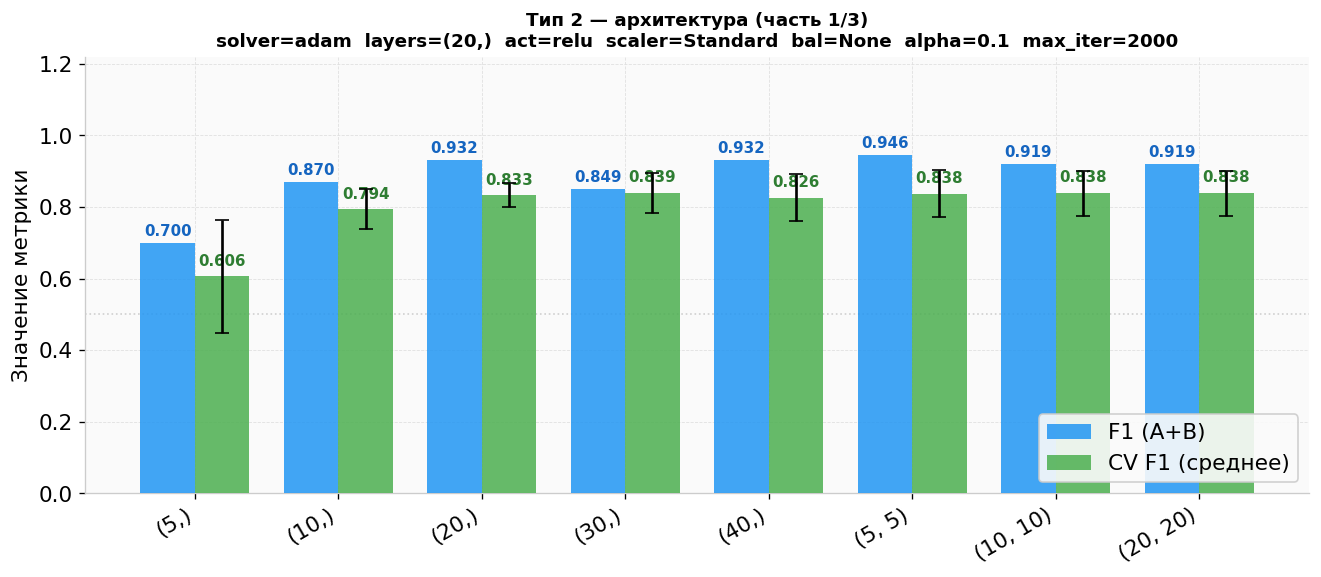

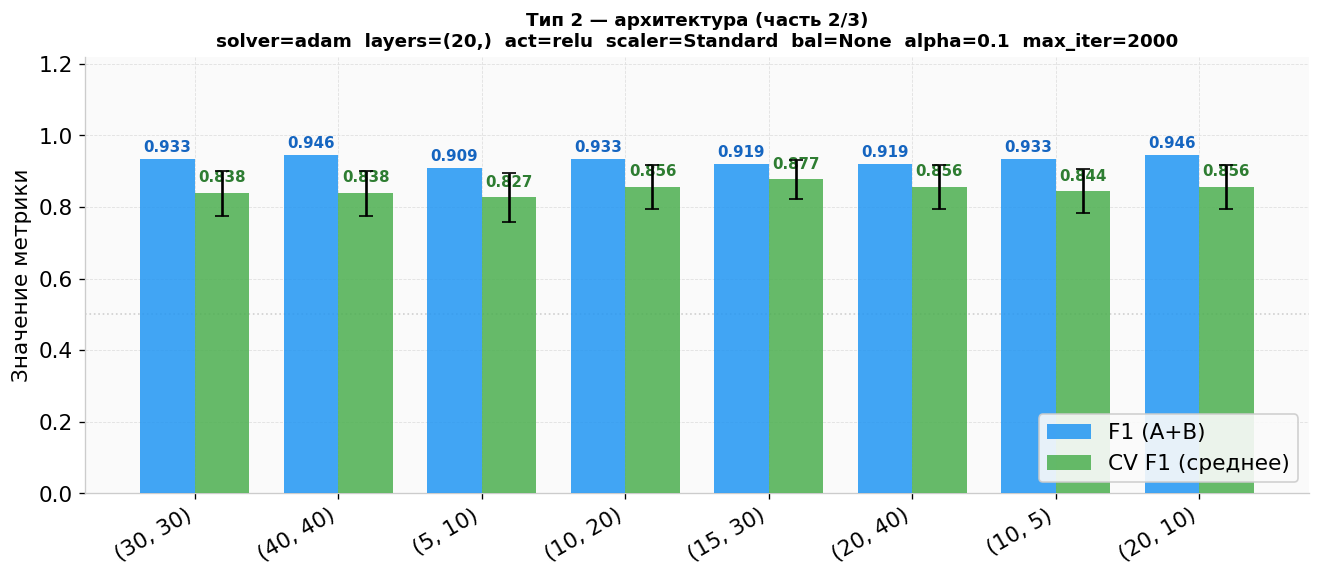

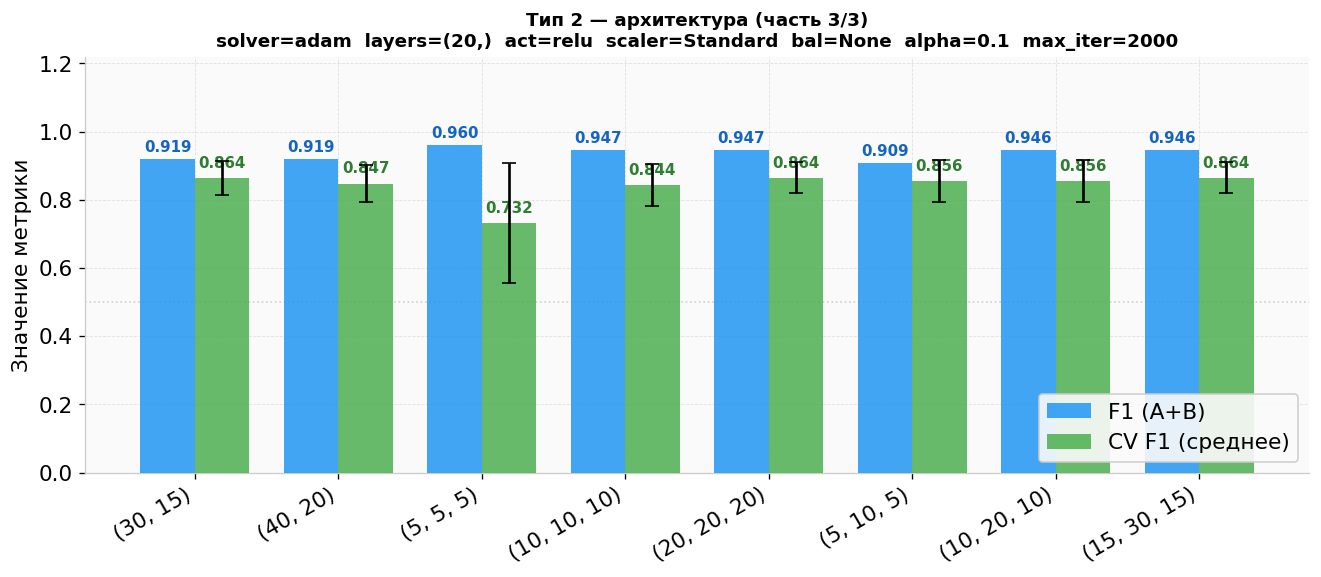

In [63]:
classifier_params[2]['activation'] = 'relu'
t = 2; p = classifier_params[t]

layers_grid = [
    (5,),(10,),(20,),(30,),(40,),
    (5,5),(10,10),(20,20),(30,30),(40,40),
    (5,10),(10,20),(15,30),(20,40),
    (10,5),(20,10),(30,15),(40,20),
    (5,5,5),(10,10,10),(20,20,20),
    (5,10,5),(10,20,10),(15,30,15),
]
results = []
for layers in layers_grid:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'layers': layers})
    results.append({'label': str(layers), 'f1': r['f1'], 'cv': r['cv']})

for i, part in enumerate(np.array_split(results, 3)):
    plot_experiment_results(list(part),
        title=f'Тип {t} — архитектура (часть {i+1}/3)\n{params_info(p)}')


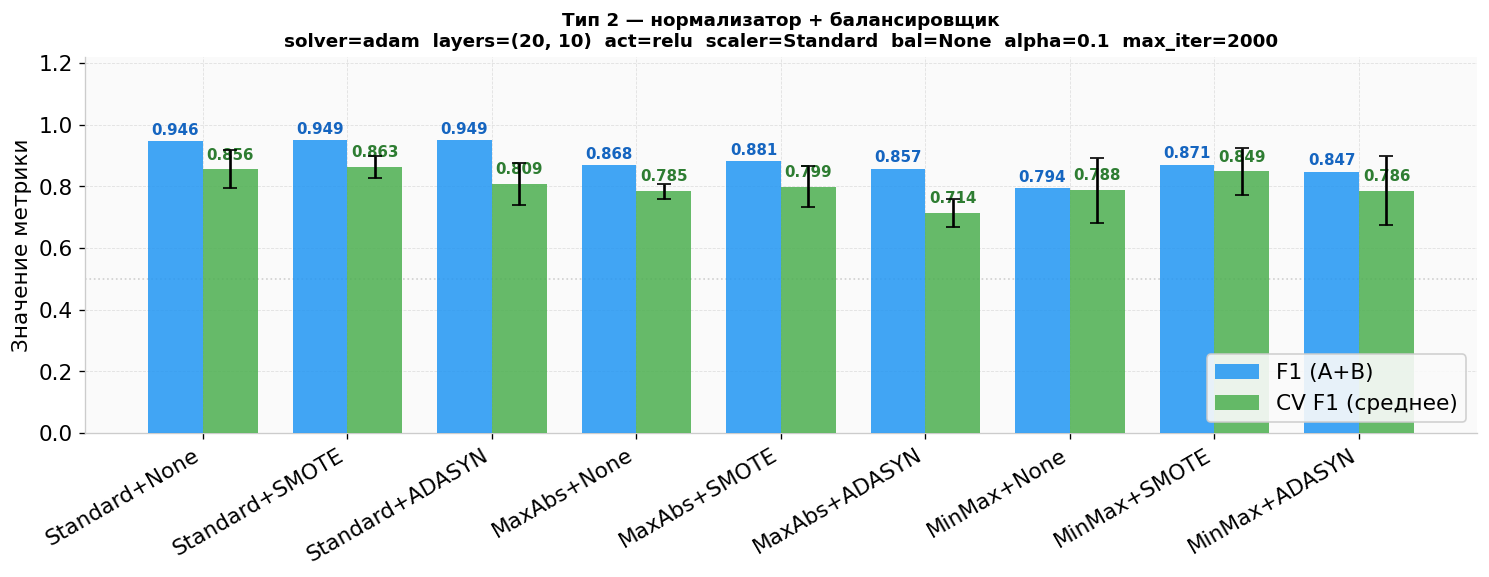

In [64]:
classifier_params[2]['layers'] = (20, 10)
t = 2; p = classifier_params[t]

results = []
for scaler in SCALERS:
    for balancer in BALANCERS:
        r = run_pipeline(surface_type=t, classifier_params={**p, 'scaler': scaler, 'balancer': balancer})
        results.append({'label': f'{scaler}+{balancer}', 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — нормализатор + балансировщик\n{params_info(p)}')


In [65]:
classifier_params[2]['scaler']   = 'Standard'
classifier_params[2]['balancer'] = 'None'
print(classifier_params[2])


{'scaler': 'Standard', 'balancer': 'None', 'solver': 'adam', 'layers': (20, 10), 'activation': 'relu', 'alpha': 0.1, 'max_iter': 2000}


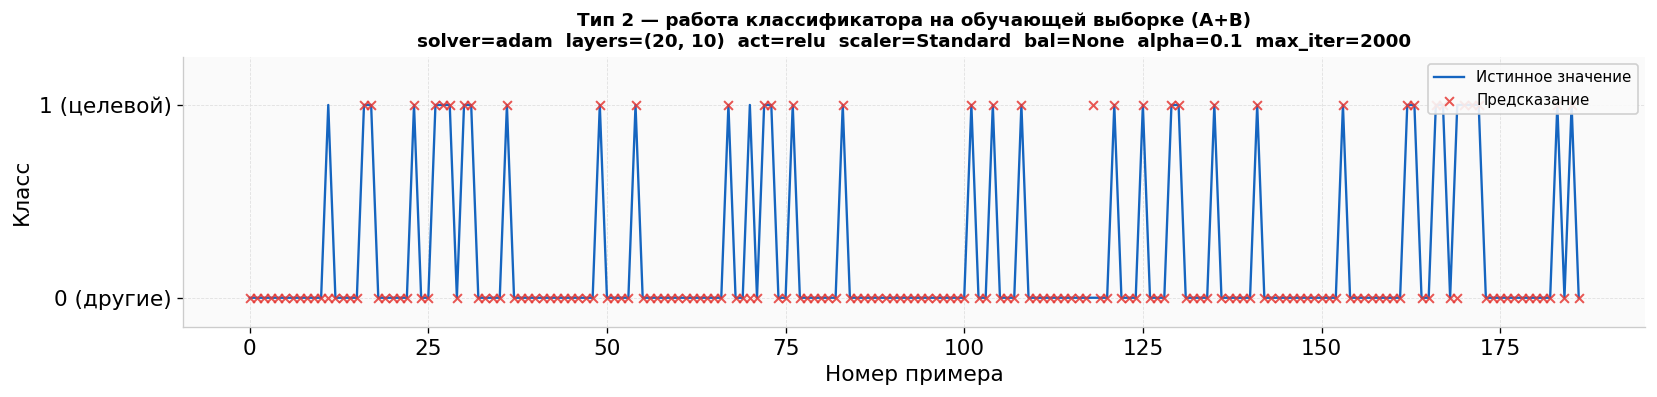

F1 на обучающей выборке: 0.9459,  CV F1: 0.8556 ± 0.0616


In [66]:
# Визуализация работы бинарного классификатора Тип 2 на обучающей выборке
t = 2; p = classifier_params[t]
r = run_pipeline(surface_type=t, classifier_params=p)
plot_binary_classifier(r['y_train'], r['pred_train'],
    title=f'Тип {t} — работа классификатора на обучающей выборке (A+B)\n{params_info(p)}')
print(f'F1 на обучающей выборке: {r["f1"]:.4f},  CV F1: {np.mean(r["cv"]):.4f} ± {np.std(r["cv"]):.4f}')


---
## Классификатор — Тип 4

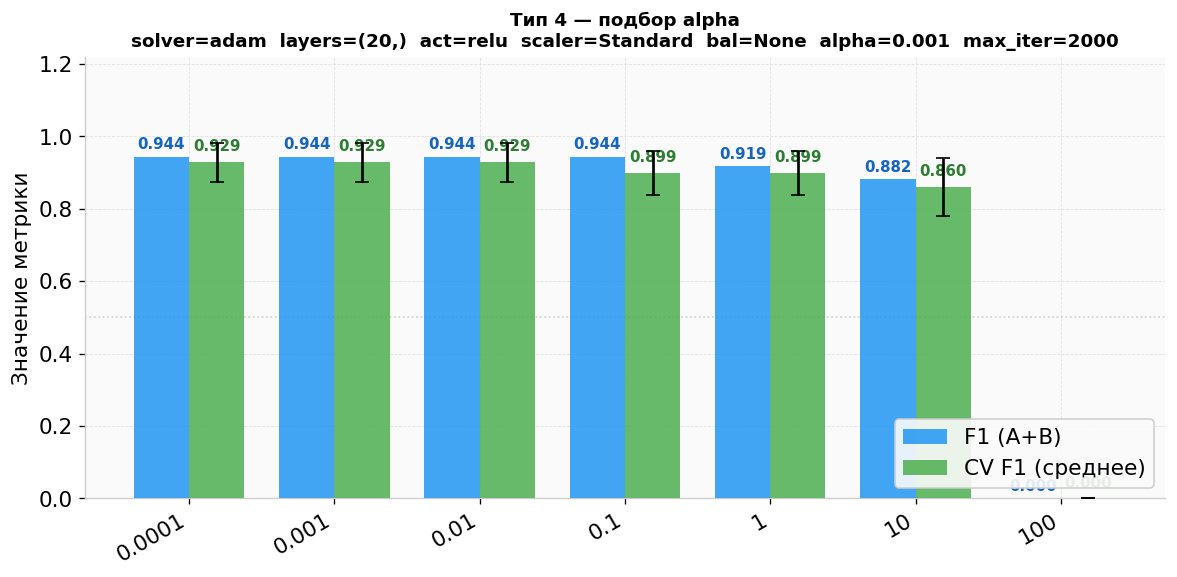

In [67]:
t = 4; p = classifier_params[t]

results = []
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'alpha': alpha})
    results.append({'label': str(alpha), 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — подбор alpha\n{params_info(p)}')


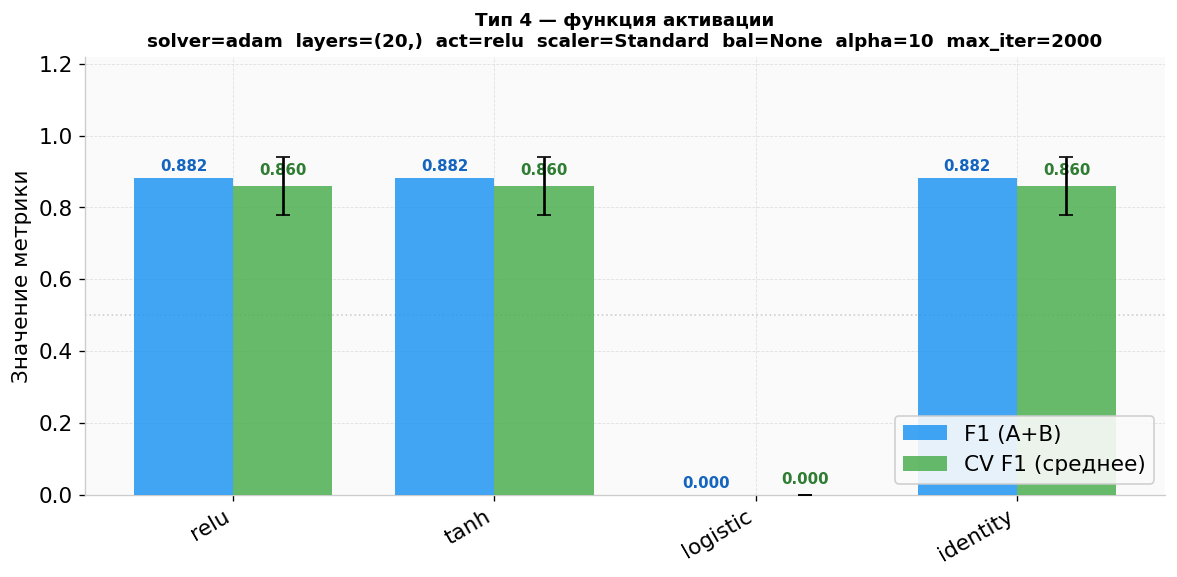

In [68]:
classifier_params[4]['alpha'] = 10
t = 4; p = classifier_params[t]

results = []
for act in ['relu', 'tanh', 'logistic', 'identity']:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'activation': act})
    results.append({'label': act, 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — функция активации\n{params_info(p)}')


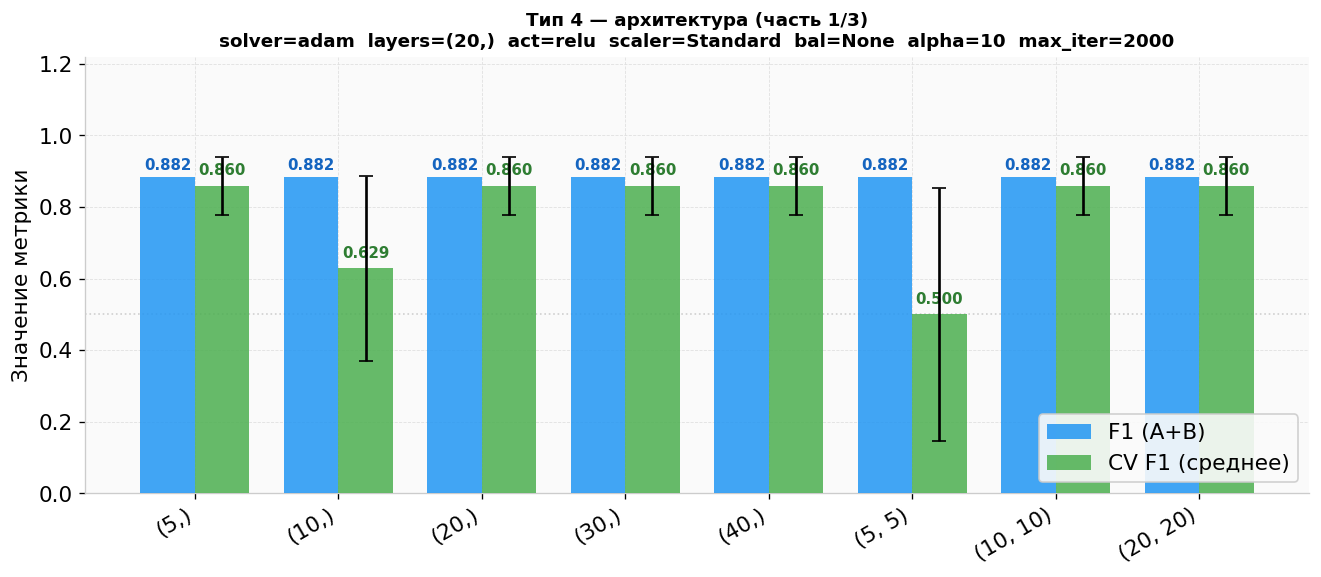

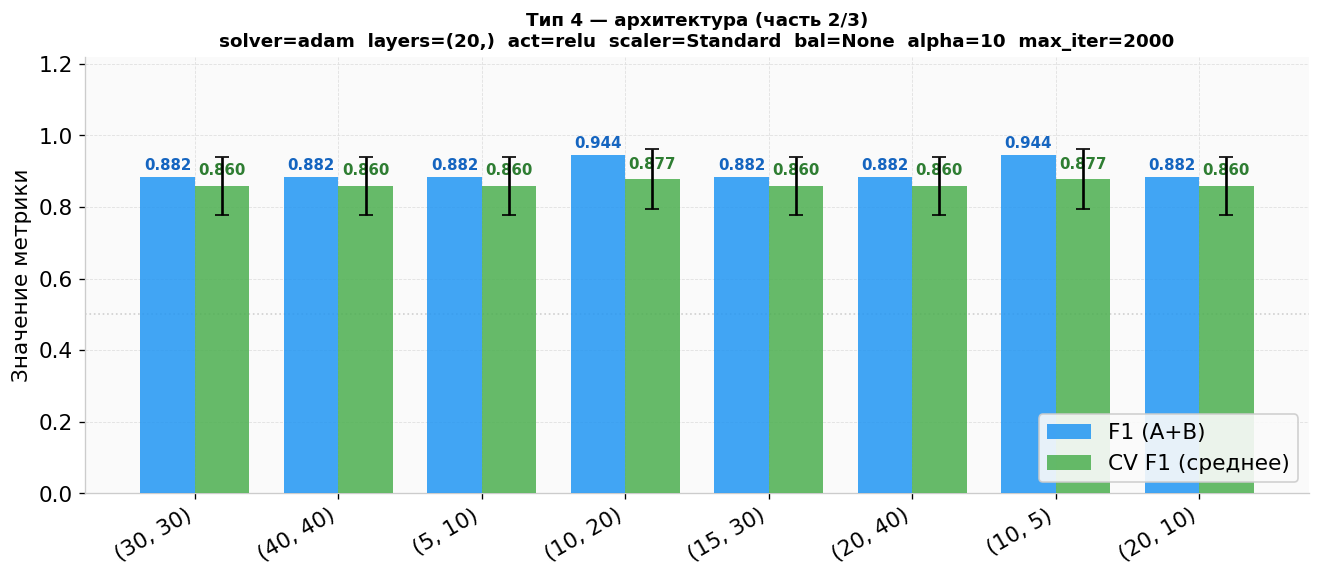

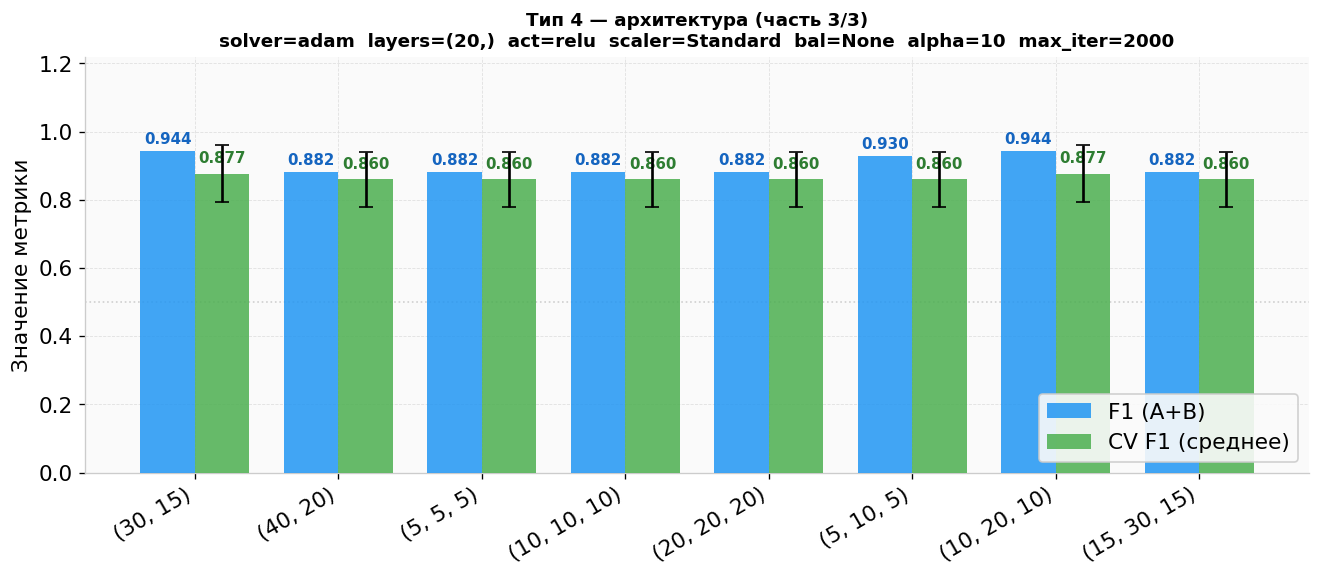

In [69]:
classifier_params[4]['activation'] = 'relu'
t = 4; p = classifier_params[t]

layers_grid = [
    (5,),(10,),(20,),(30,),(40,),
    (5,5),(10,10),(20,20),(30,30),(40,40),
    (5,10),(10,20),(15,30),(20,40),
    (10,5),(20,10),(30,15),(40,20),
    (5,5,5),(10,10,10),(20,20,20),
    (5,10,5),(10,20,10),(15,30,15),
]
results = []
for layers in layers_grid:
    r = run_pipeline(surface_type=t, classifier_params={**p, 'layers': layers})
    results.append({'label': str(layers), 'f1': r['f1'], 'cv': r['cv']})

for i, part in enumerate(np.array_split(results, 3)):
    plot_experiment_results(list(part),
        title=f'Тип {t} — архитектура (часть {i+1}/3)\n{params_info(p)}')


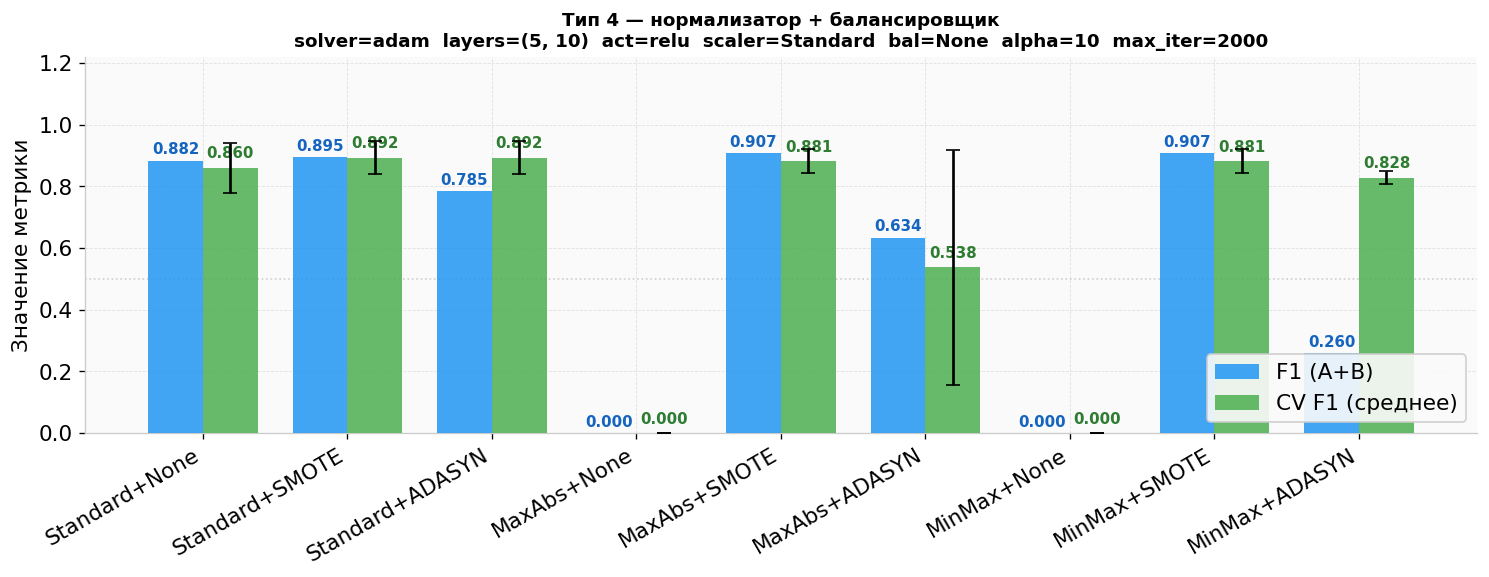

In [70]:
classifier_params[4]['layers'] = (5, 10)
t = 4; p = classifier_params[t]

results = []
for scaler in SCALERS:
    for balancer in BALANCERS:
        r = run_pipeline(surface_type=t, classifier_params={**p, 'scaler': scaler, 'balancer': balancer})
        results.append({'label': f'{scaler}+{balancer}', 'f1': r['f1'], 'cv': r['cv']})

plot_experiment_results(results,
    title=f'Тип {t} — нормализатор + балансировщик\n{params_info(p)}')


In [71]:
classifier_params[4]['scaler']   = 'Standard'
classifier_params[4]['balancer'] = 'None'


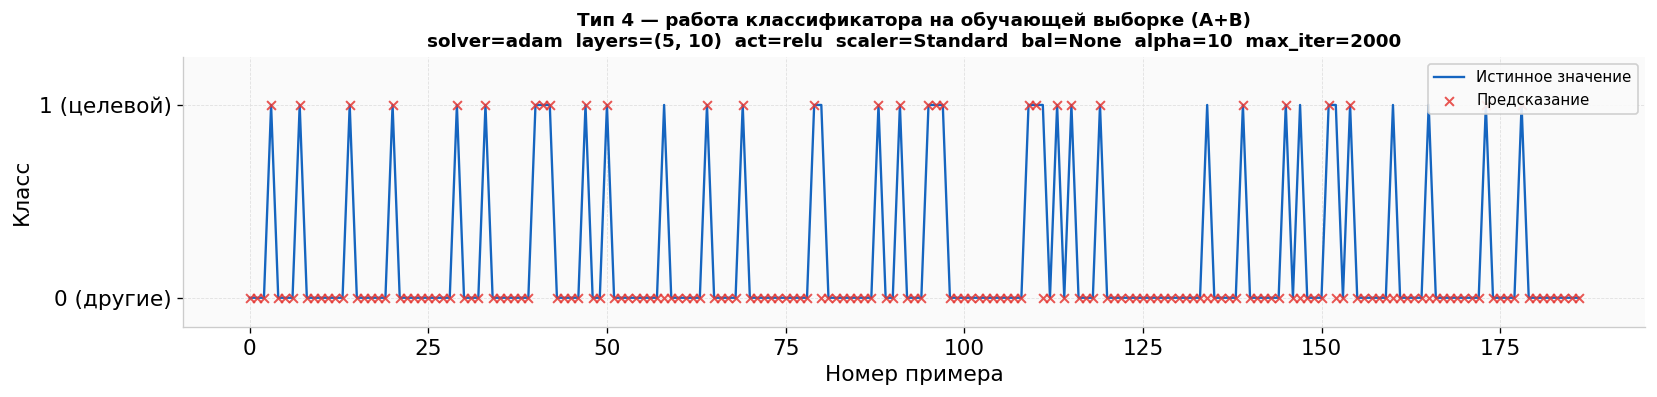

F1 на обучающей выборке: 0.8824,  CV F1: 0.8597 ± 0.0809


In [72]:
# Визуализация работы бинарного классификатора Тип 4 на обучающей выборке
t = 4; p = classifier_params[t]
r = run_pipeline(surface_type=t, classifier_params=p)
plot_binary_classifier(r['y_train'], r['pred_train'],
    title=f'Тип {t} — работа классификатора на обучающей выборке (A+B)\n{params_info(p)}')
print(f'F1 на обучающей выборке: {r["f1"]:.4f},  CV F1: {np.mean(r["cv"]):.4f} ± {np.std(r["cv"]):.4f}')


---
## Финальный ансамбль

Обучаем три бинарных классификатора с итоговыми параметрами из `classifier_params`.


In [73]:
print('Итоговые параметры:')
for t, p in classifier_params.items():
    print(f'  Тип {t}: {p}')


Итоговые параметры:
  Тип 1: {'scaler': 'Standard', 'balancer': 'None', 'solver': 'adam', 'layers': (20, 20), 'activation': 'tanh', 'alpha': 0.1, 'max_iter': 3500}
  Тип 2: {'scaler': 'Standard', 'balancer': 'None', 'solver': 'adam', 'layers': (20, 10), 'activation': 'relu', 'alpha': 0.1, 'max_iter': 2000}
  Тип 4: {'scaler': 'Standard', 'balancer': 'None', 'solver': 'adam', 'layers': (5, 10), 'activation': 'relu', 'alpha': 10, 'max_iter': 2000}


In [74]:
# Обучаем модели с использованием подобранных параметров
# classifier_params это словарь с параметрами классификаторов (функция активации, количество слоев и так далее)
# В него записывались оптимальные параметры в процессе исследования
final_models = {}
for t, p in classifier_params.items():
    r = run_pipeline(
        surface_type=t,
        classifier_params=p,
        cv=3
    )
    final_models[t] = r['model']
    # print(f'Тип {t}  F1(A+B)={r["f1"]:.4f}  '
    #       f'CV={np.mean(r["cv"]):.4f} ± {np.std(r["cv"]):.4f}')


### Сохранение и загрузка моделей

Модели ансамбля (пайплайны `Scaler -> MLP`) сохраняются в папку `models` и могут быть загружены без повторного обучения. Для предсказания нужны также `compute_V2`, `FEAT_V2` и `ensemble_predict`.

In [ ]:
import joblib
from pathlib import Path

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

for t, model in final_models.items():
    joblib.dump(model, MODELS_DIR / f'ensemble_type_{t}.joblib')
    print(f'Сохранено: {MODELS_DIR / f"ensemble_type_{t}.joblib"}')


In [ ]:
import joblib
from pathlib import Path

MODELS_DIR = Path('models')

final_models = {t: joblib.load(MODELS_DIR / f'ensemble_type_{t}.joblib') for t in [1, 2, 4]}
print('Загружены модели для типов:', list(final_models))


In [75]:
# def ensemble_predict(X_raw):
#     """Предсказывает тип поверхности ансамблем трёх
#     бинарных классификаторов.

#     Возвращает (y_pred, P) где P — матрица вероятностей (N×3).
#     Если максимальная вероятность < THRESHOLD → присваивается класс 0
#     (неизвестная поверхность).
#     """    
#     THRESHOLD = 0.5
#     known = [1, 2, 4]
#     X_feat = compute_V2(X_raw)[FEAT_V2]
#     probs_list = [final_models[t].predict_proba(X_feat)[:, 1] for t in known]
#     P = np.column_stack(probs_list)
#     best_idx  = np.argmax(P, axis=1)
#     max_probs = P[np.arange(len(P)), best_idx]
#     best_type = np.array(known)[best_idx]
#     return np.where(max_probs >= THRESHOLD, best_type, 0), P

def ensemble_predict(X_raw):
    """Предсказывает тип поверхности ансамблем трёх
    бинарных классификаторов.

    Возвращает (y_pred, P) где P — матрица вероятностей (N×3).
    Если максимальная вероятность < THRESHOLD → присваивается класс 0
    (неизвестная поверхность).
    """
    THRESHOLD = 0.5
    types = [1, 2, 4]
    X_feat = compute_V2(X_raw)[FEAT_V2]

    probs_list = []
    for t in types:
        prob = final_models[t].predict_proba(X_feat)[:, 1]
        probs_list.append(prob)
    P = np.column_stack(probs_list)
    
    best_idx  = np.argmax(P, axis=1)
    max_probs = P[np.arange(len(P)), best_idx]
    best_type = np.array(types)[best_idx]
    return np.where(max_probs >= THRESHOLD, best_type, 0), P


def evaluate_ensemble(df_input, title=''):
    """Матрица ошибок + scatter-график предсказаний."""    
    X_raw  = df_input.drop('Type', axis=1)
    y_true = df_input['Type']
    known  = [1, 2, 4]
    labels_str = {0: 'Неизв.', 1: 'Тип 1', 2: 'Тип 2', 4: 'Тип 4'}

    y_pred, P = ensemble_predict(X_raw)
    y_mapped  = y_true.map(lambda t: t if t in known else 0)
    all_cls   = sorted(set(y_mapped) | set(y_pred))
    tick_lbl  = [labels_str.get(c, str(c)) for c in all_cls]

    print(f'\n{"="*60}')
    print(f'  {title}')
    print(f'{"="*60}')
    print(classification_report(y_mapped, y_pred,
          labels=all_cls, target_names=tick_lbl, zero_division=0))

    order   = np.argsort(y_mapped.values, kind='stable')
    yt_s    = y_mapped.values[order]
    yp_s    = np.array(y_pred)[order]
    correct = yt_s == yp_s
    cm      = confusion_matrix(y_mapped, y_pred, labels=all_cls)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

    # Матрица ошибок
    im = ax1.imshow(cm, cmap='Blues')
    ax1.set_xticks(range(len(all_cls))); ax1.set_xticklabels(tick_lbl)
    ax1.set_yticks(range(len(all_cls))); ax1.set_yticklabels(tick_lbl)
    ax1.set_xlabel('Предсказанный'); ax1.set_ylabel('Истинный')
    ax1.set_title('Матрица ошибок')
    for i in range(len(all_cls)):
        for j in range(len(all_cls)):
            ax1.text(j, i, str(cm[i,j]), ha='center', va='center',
                     color='white' if cm[i,j] > cm.max()*0.5 else 'black',
                     fontsize=13, fontweight='bold')
    fig.colorbar(im, ax=ax1, shrink=0.8)

    # Предсказания vs Истина
    bnd = np.where(np.diff(yt_s) != 0)[0] + 1
    ax2.scatter(np.where(correct)[0],   yt_s[correct],  s=25,
                c='#4CAF50', label='Верно', alpha=0.8, zorder=3)
    ax2.scatter(np.where(~correct)[0],  yt_s[~correct], s=25,
                c='#9E9E9E', label='Истинный (ошибка)', alpha=0.6, zorder=3)
    ax2.scatter(np.where(~correct)[0],  yp_s[~correct], s=40,
                c='#E53935', marker='x', label='Предсказанный (ошибка)', lw=1.4, zorder=4)
    for b in bnd:
        ax2.axvline(b - 0.5, color='#BDBDBD', ls='--', alpha=0.5, lw=0.8)
    seg = [0] + list(bnd) + [len(yt_s)]
    for s in range(len(seg)-1):
        lo, hi = seg[s], seg[s+1]
        ax2.text((lo+hi)/2, -0.7, labels_str.get(yt_s[lo], str(yt_s[lo])),
                 ha='center', fontsize=10, color='#555', fontweight='bold')
    ax2.set_yticks(all_cls); ax2.set_yticklabels(tick_lbl)
    ax2.set_xlabel('Номер примера'); ax2.set_ylabel('Класс')
    ax2.set_title(f'Предсказания vs Истина  |  Accuracy: {correct.mean():.1%}')
    ax2.legend(loc='upper left', fontsize=9, framealpha=0.9)
    ax2.set_ylim(-1.3, max(all_cls) + 0.5)

    # Подзаголовок с полной конфигурацией
    cfg = '\n'.join(f'Тип {t}: {params_info(classifier_params[t])}' for t in [1,2,4])
    fig.suptitle(f'{title}\n{cfg}', fontsize=9, fontweight='bold')
    plt.tight_layout(); plt.show()

def plot_ensemble_results(df, title=''):
    THRESHOLD = 0.5
    SURFACE_CLASSES = [1, 2, 4]

    X_raw  = df.drop('Type', axis=1)   # сырые данные!
    y_true = df['Type']

    order    = np.argsort(y_true.values, kind='stable')
    X_sorted = X_raw.iloc[order].reset_index(drop=True)
    y_sorted = y_true.iloc[order].reset_index(drop=True)

    # preds, probs = ensemble_predict(X_sorted, classifiers, features_dict, bounds_dict)
    preds, probs = ensemble_predict(X_sorted)

    bnd = np.where(np.diff(y_sorted) != 0)[0] + 1

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                    gridspec_kw={'height_ratios': [1, 1]})

    ax1.scatter(range(len(y_sorted)), y_sorted, s=18, c='#333333', marker='o',
                zorder=4, label='Истинный класс', alpha=0.8)
    ax1.scatter(range(len(preds)), preds, s=30, c='#E53935', marker='x',
                zorder=5, linewidths=1.2, label='Прогноз ансамбля', alpha=0.85)
    for b in bnd:
        ax1.axvline(b - 0.5, color='#BDBDBD', ls='--', alpha=0.6, lw=0.8)
    ax1.set_yticks([0, 1, 2, 3, 4, 5])
    ax1.set_ylabel('Класс')
    ax1.set_title(title, fontsize=13, fontweight='bold')
    ax1.legend(loc='upper right', framealpha=0.9, fontsize=10)

    class_to_idx = {c: i for i, c in enumerate([1, 2, 4])}
    for c in SURFACE_CLASSES:
        idx = class_to_idx[c]
        ax2.plot(probs[:, idx], color=COLORS[c], lw=1.5, label=f'P(тип {c})', alpha=0.85)
        ax2.fill_between(range(len(probs)), probs[:, idx], alpha=0.08, color=COLORS[c])

    ax2.axhline(THRESHOLD, color='#555', ls=':', lw=1.2, label=f'Порог={THRESHOLD}')
    for b in bnd:
        ax2.axvline(b - 0.5, color='#BDBDBD', ls='--', alpha=0.6, lw=0.8)

    seg = [0] + list(bnd) + [len(y_sorted)]
    for s in range(len(seg) - 1):
        lo, hi = seg[s], seg[s + 1]
        ax2.text((lo + hi) / 2, 1.04, f'тип {y_sorted[lo]}', ha='center',
                 transform=ax2.get_xaxis_transform(), fontsize=11,
                 color='#555', fontweight='bold')

    ax2.set_ylim(-0.05, 1.12)
    ax2.set_xlabel('Номер примера')
    ax2.set_ylabel('Вероятность')
    ax2.legend(loc='upper right', ncol=len(SURFACE_CLASSES) + 1, framealpha=0.9, fontsize=9)

    plt.tight_layout()
    plt.show()

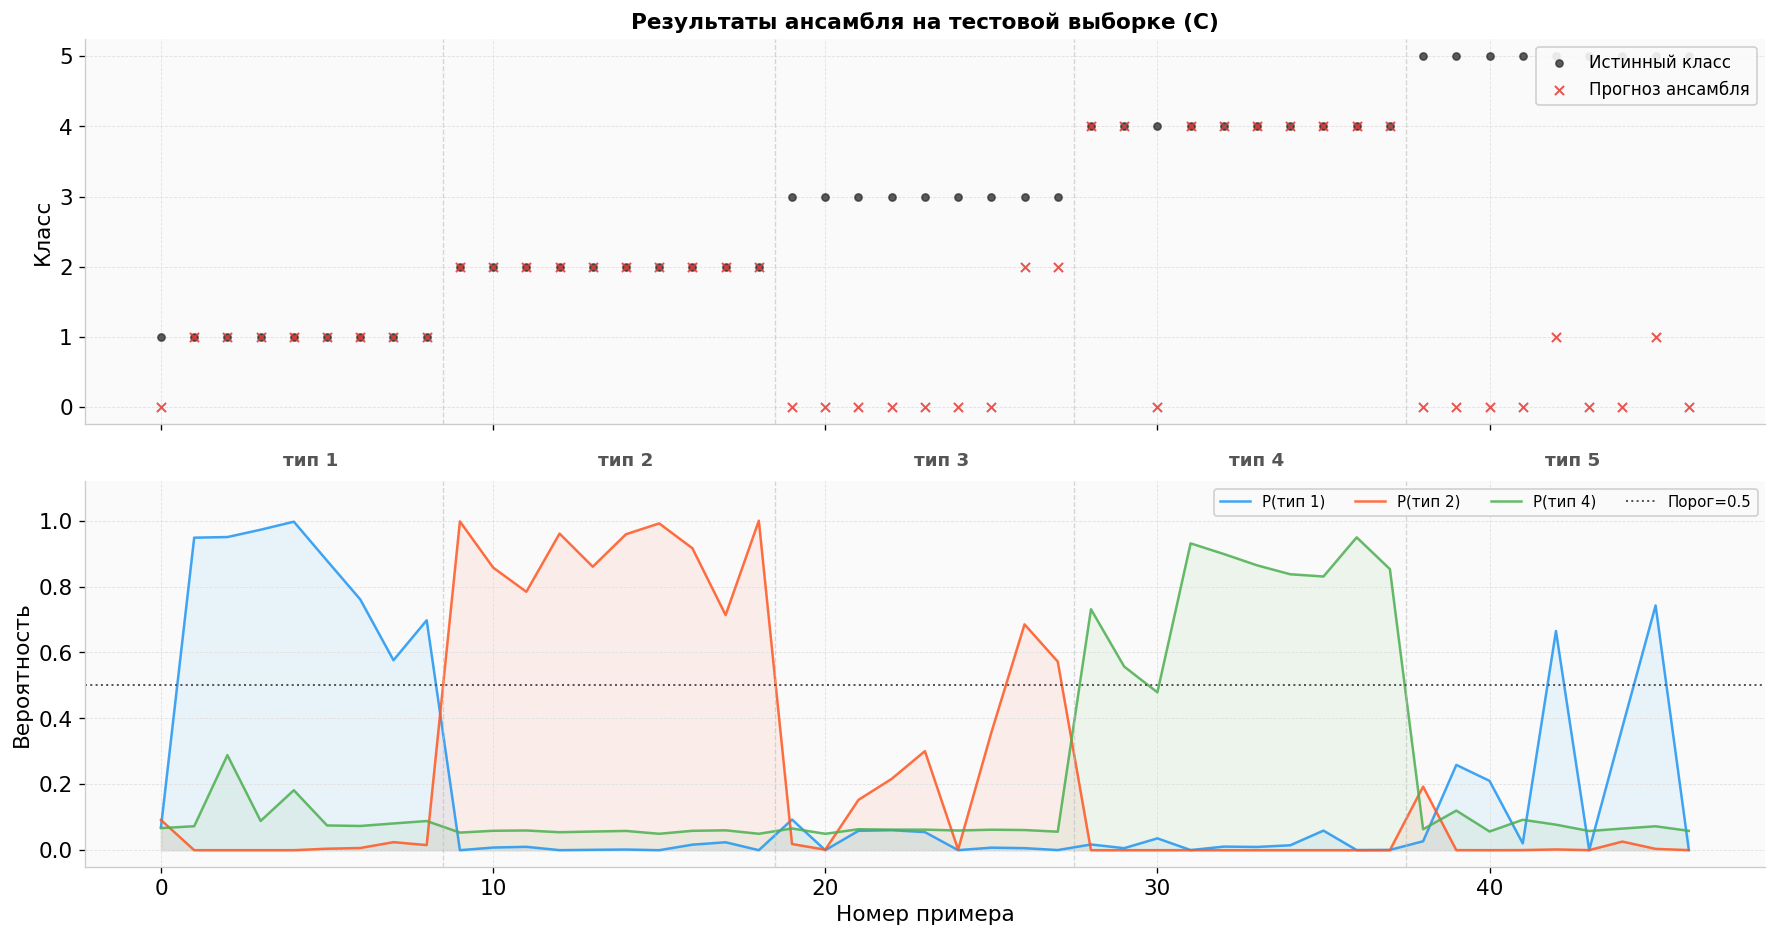


  Контрольная выборка C
              precision    recall  f1-score   support

      Неизв.       0.88      0.78      0.82        18
       Тип 1       0.80      0.89      0.84         9
       Тип 2       0.83      1.00      0.91        10
       Тип 4       1.00      0.90      0.95        10

    accuracy                           0.87        47
   macro avg       0.88      0.89      0.88        47
weighted avg       0.88      0.87      0.87        47



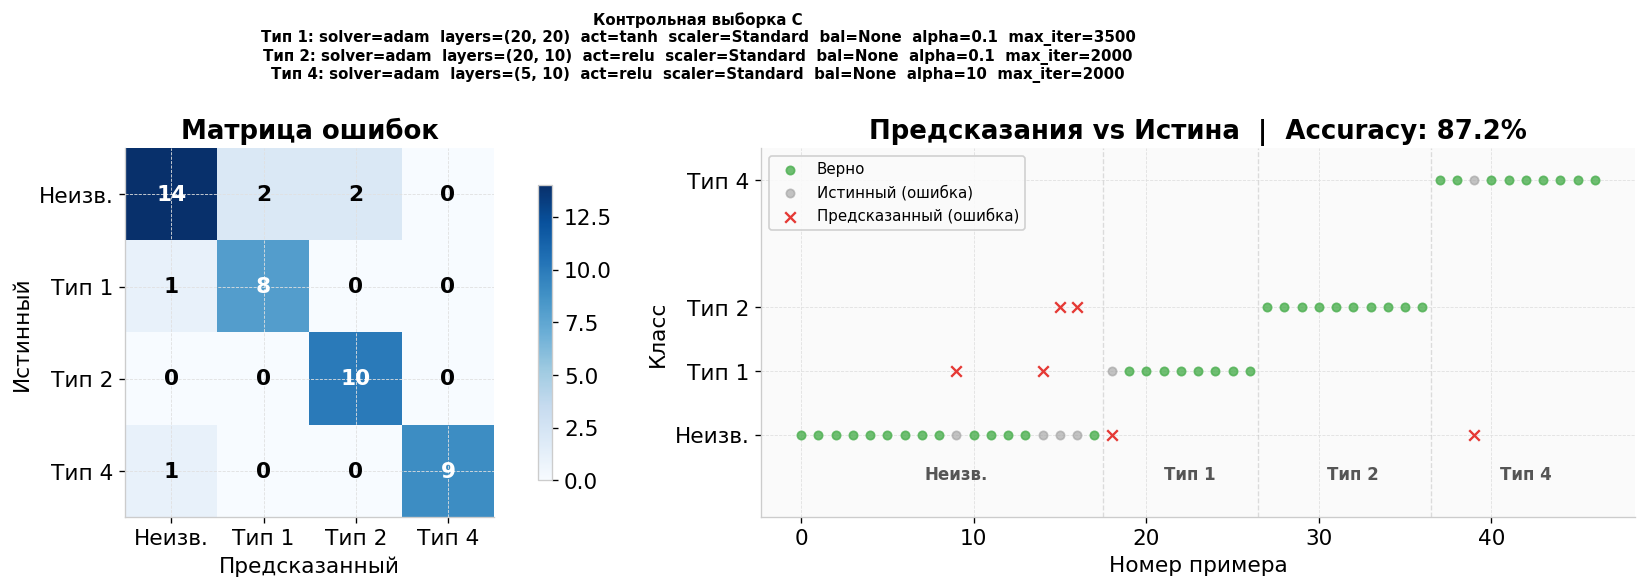

In [76]:
plot_ensemble_results(df_C, title='Результаты ансамбля на тестовой выборке (C)')
                      
evaluate_ensemble(df_C_raw, title='Контрольная выборка C')


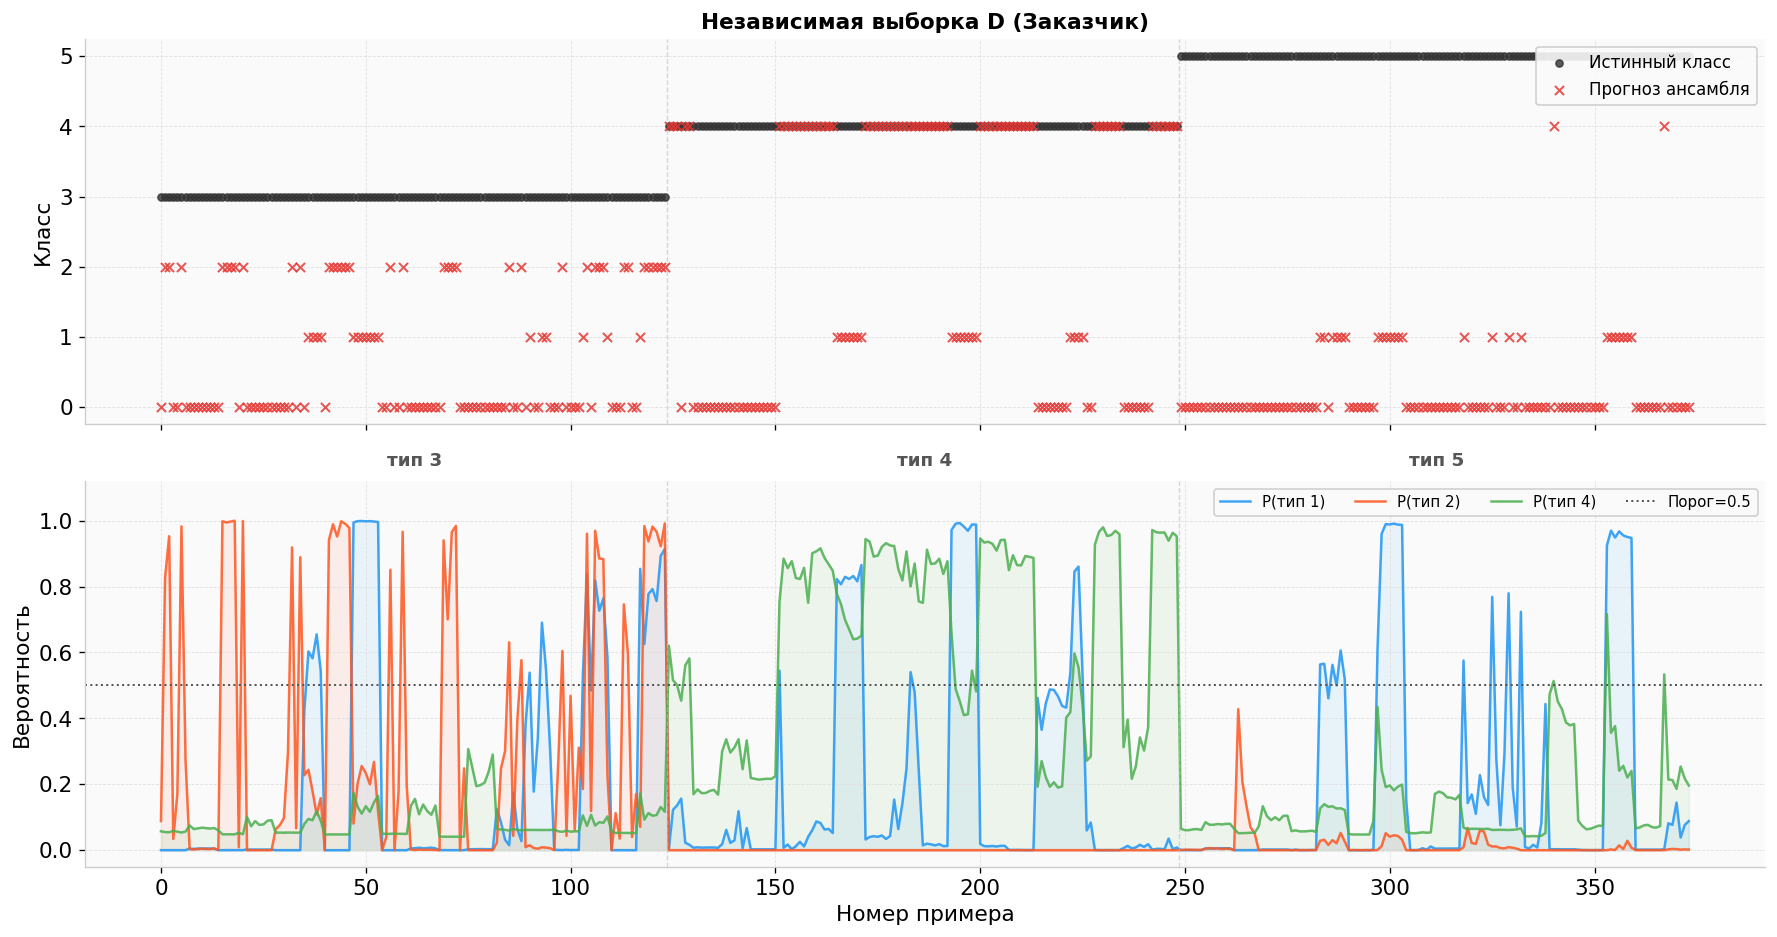


  Независимая выборка D (Заказчик)
              precision    recall  f1-score   support

      Неизв.       0.81      0.68      0.74       249
       Тип 1       0.00      0.00      0.00         0
       Тип 2       0.00      0.00      0.00         0
       Тип 4       0.97      0.54      0.70       125

    accuracy                           0.63       374
   macro avg       0.45      0.31      0.36       374
weighted avg       0.87      0.63      0.73       374



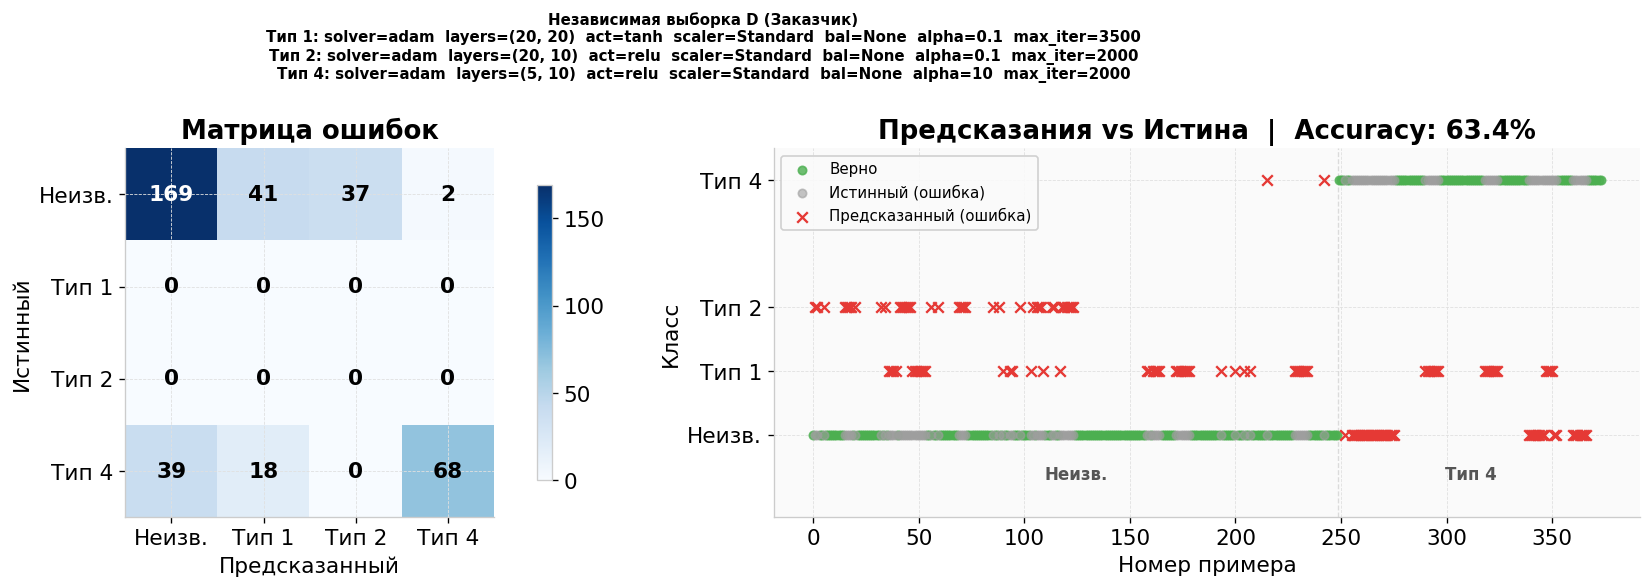

In [77]:
df_D = pd.read_excel('D_data.xlsx')

plot_ensemble_results(df_D, title='Независимая выборка D (Заказчик)')
evaluate_ensemble(df_D, title='Независимая выборка D (Заказчик)')
